# Prédiction précoce du sepsis (Early Sepsis Prediction) avec LSTM + Évolution Différentielle (DE)

**Réalisé par :** SOHAYEB GASMI · IKRAM EL GHIDOUNI · CHAYMAE AL AISSAOUI

**Données :** PhysioNet/Computing in Cardiology Challenge 2019 (gratuites, sans inscription)  
**Modèle :** LSTM (PyTorch) qui prédit, heure par heure, si le patient va entrer en sepsis dans les prochaines heures  
**Méta-heuristique :** Évolution Différentielle (DE) écrite **entièrement de zéro** pour optimiser les hyperparamètres du LSTM

### Que fait ce notebook ?
| # | Section | Sorties |
|---|---------|---------|
| 1 | Chargement des données + EDA | tableaux récapitulatifs, valeurs manquantes, distributions, trajectoires des signes vitaux autour du début du sepsis, corrélations |
| 2 | Prétraitement | séparation par patient, ffill, masques, normalisation, fenêtres temporelles |
| 3 | Explication du LSTM et équations | équations + construction du modèle |
| 4 | **Explication détaillée de DE** | mutation, croisement, sélection, stratégies, jDE, exemple numérique |
| 5 | **Test de la robustesse de DE sur des fonctions de référence** | courbes de convergence, tableaux, sensibilité à F/CR/NP, visualisation 2D de la population |
| 6 | **DE ⟷ LSTM** | recherche des meilleurs paramètres, comparaison avec Random Search et avec la configuration manuelle (même budget) |
| 7 | Évaluation finale | ROC, PR, calibration, confusion, seuil de décision, évaluation au niveau patient, Bootstrap |
| 8 | Conclusion | quantification du rôle et de la robustesse de DE |

> **Mode d'emploi :** modifiez la variable `MODE` dans la première cellule de code. Utilisez un GPU (Colab : Runtime ▸ Change runtime type ▸ T4).  
> `tiny` = essai rapide pour vérifier que tout fonctionne, `fast` = ~40-70 minutes sur GPU (recommandé), `medium`/`full` = résultats plus solides.

## 0) Conception expérimentale : quel est le rôle de DE et comment mesurer sa robustesse ?

**Question de recherche :** DE donne-t-il au LSTM de meilleurs résultats que (a) une configuration manuelle raisonnable, et (b) une recherche aléatoire avec le même nombre d'essais ?


**Trois bras avec le même budget de calcul (nombre d'entraînements du LSTM) :**
1. **Default** : configuration manuelle courante (hidden=64, layers=1, dropout=0.2, lr=1e-3, wd=1e-5, T=12).
2. **Random Search (RS)** : échantillons aléatoires uniformes dans le même espace.
3. **DE** : recherche évolutionnaire guidée.

**Comment déterminer la « robustesse » de DE ?** À travers 5 preuves :
- Courbe de la meilleure valeur obtenue jusqu'ici (best-so-far) en fonction du nombre d'évaluations (DE vs RS).
- Distribution de la qualité de tous les essais (DE concentre-t-il les échantillons dans la bonne région ?).
- Convergence de la population (diversité) et taux de succès des enfants (Success rate).
- Performance finale sur **Test** (jamais utilisé pour la sélection) avec plusieurs seeds, IC Bootstrap et test de différence appariée.
- Test indépendant sur des fonctions de référence (Sphere, Rastrigin, Rosenbrock, Ackley) qui montre les propriétés de DE sans le bruit du LSTM.

### Corrections appliquées (version révisée)
Diagnostic de la version précédente : le meilleur epoch de validation était **1 ou 2 sur 30** (sur-apprentissage immédiat : seulement 778 patients septiques en train), AUPRC test ≈ 0.08 (prévalence 0.017), rappel ≈ 14 %.

1. `n_patients=None` : utilisation des **40 336 patients** (≈ 3,5× plus de patients septiques).
2. Nouvelles features : **temps écoulé depuis la dernière mesure** (`*_dt`).
3. Régularisation : bruit gaussien sur l'entrée (`INPUT_NOISE`), dropout ≥ 0.2, lr ≤ 3e-3.
4. Validation 2× plus fréquente (`EP_FRAC=0.5`), `epochs_search=10`, `final_epochs=60`, `patience=10`.


In [1]:
# ============================ 1) Configuration et bibliothèques ============================
import os, sys, time, math, copy, json, random, warnings, subprocess, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, matthews_corrcoef, brier_score_loss)
from sklearn.calibration import calibration_curve
try:
    from tqdm.auto import tqdm
except ImportError:                      # solution de repli simple si tqdm n'est pas installé
    def tqdm(x, **k): return x
try:
    from IPython.display import display
except ImportError:
    display = print
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9})

# ------------------------------- Choisir le mode d'exécution -------------------------------
MODE = "fast"        # "tiny" | "fast" | "medium" | "full"

PRESETS = {
    #            patients | ratio nég:pos | epochs recherche | NP | G | epochs final | seeds finaux | éch. val | benchmark | bootstrap | neg final | seeds de l'objectif
    "tiny":   dict(n_patients=1500,  neg_ratio=6, epochs_search=2, de_pop=6,  de_gen=3,  final_epochs=6,  n_seeds=2, val_rows=15000,  bench_runs=3,  boot=30,  final_neg_ratio=6, obj_seeds=1),
    "fast":   dict(n_patients=None, neg_ratio=8, epochs_search=10, de_pop=20, de_gen=10, final_epochs=60, n_seeds=3, val_rows=80000,  bench_runs=5,  boot=200, final_neg_ratio=8, obj_seeds=2),
    "medium": dict(n_patients=None,  neg_ratio=8, epochs_search=5, de_pop=24, de_gen=12, final_epochs=40, n_seeds=5, val_rows=120000, bench_runs=10, boot=300, final_neg_ratio=8, obj_seeds=2),
    "full":   dict(n_patients=None,  neg_ratio=8, epochs_search=6, de_pop=30, de_gen=15, final_epochs=50, n_seeds=5, val_rows=150000, bench_runs=15, boot=300, final_neg_ratio=8, obj_seeds=3),
}
CFG = PRESETS[MODE]
SEED = 42
WMAX = 32            # plus grande longueur de fenêtre temporelle (heures) autorisée par l'espace de recherche
BATCH = 256
EP_FRAC = 0.5         # [FIX] un "epoch" = 50% des positifs -> validation 2x plus fréquente (le pic de val arrivait à l'epoch 1)
INPUT_NOISE = 0.1    # [FIX] bruit gaussien sur les entrées pendant le train (régularisation contre le sur-apprentissage)
POS_W_POWER = 0.5    # pos_weight = (neg_ratio) ** POS_W_POWER
DE_STRATEGY = "currenttobest1bin"
DE_F, DE_CR = 0.6, 0.9

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"MODE={MODE} | device={DEVICE} | CFG={CFG}")
if DEVICE.type == "cpu" and MODE in ("medium", "full"):
    print("Pas de GPU : ce mode sera très lent. Essayez MODE='tiny' ou 'fast'.")

FIG_DIR, TAB_DIR = Path("figures"), Path("tables")
FIG_DIR.mkdir(exist_ok=True); TAB_DIR.mkdir(exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=170, bbox_inches="tight")
    plt.show()

def save_table(t, name, digits=4):
    t.to_csv(TAB_DIR / f"{name}.csv")
    display(t.round(digits) if isinstance(t, pd.DataFrame) else t)

MODE=fast | device=cuda | CFG={'n_patients': None, 'neg_ratio': 8, 'epochs_search': 10, 'de_pop': 20, 'de_gen': 10, 'final_epochs': 60, 'n_seeds': 3, 'val_rows': 80000, 'bench_runs': 5, 'boot': 200, 'final_neg_ratio': 8, 'obj_seeds': 2}


## 1) Chargement des données (gratuites) et lecture

Chaque patient = un fichier `.psv` (séparateur `|`), une ligne par heure en soins intensifs (ICU). Colonnes : 8 signes vitaux + 26 analyses de laboratoire + 6 variables statiques/démographiques + `SepsisLabel`.

**Définition de la cible dans ces données (important) :** selon les critères Sepsis-3, si l'instant de début clinique du sepsis est $t_{sepsis}$ alors
$$
\text{SepsisLabel}(t)=\begin{cases}1 & t \ge t_{sepsis}-6\ \text{h}\\ 0 & \text{sinon}\end{cases}
$$
c'est-à-dire que l'étiquette passe à 1 **6 heures avant** le sepsis clinique ; un modèle qui déclenche une alerte au premier `1` a donc prédit le sepsis environ 6 heures à l'avance (au minimum).  
Il n'y a pas de fuite temporelle dans la méthode suivante : le modèle ne voit que les heures $[t-T+1,\;t]$ pour prédire l'étiquette en $t$.

In [2]:
# Les données sont déjà présentes en local, avec l'arborescence suivante :
#   sepsis_data/training/training_setA/*.psv   (20 336 patients, hôpital A)
#   sepsis_data/training/training_setB/*.psv   (20 000 patients, hôpital B)
DATA_DIR = Path("sepsis_data") / "training"

def find_set(name):
    cands = [d for d in DATA_DIR.rglob(name) if d.is_dir()]
    assert cands, (f"Dossier introuvable : {DATA_DIR / name}. Lancez Jupyter depuis le dossier du projet "
                   "(celui qui contient sepsis_data/) et vérifiez l'arborescence sepsis_data/training/training_setA et training_setB")
    return cands[0]

SET_A, SET_B = find_set("training_setA"), find_set("training_setB")
n_a, n_b = len(list(SET_A.glob("*.psv"))), len(list(SET_B.glob("*.psv")))
print(f"{SET_A} : {n_a} fichiers | {SET_B} : {n_b} fichiers | total = {n_a + n_b}")
assert n_a > 0 and n_b > 0, "Aucun fichier .psv trouvé dans training_setA ou training_setB"

sepsis_data/training/training_setA : 20336 fichiers | sepsis_data/training/training_setB : 20000 fichiers | total = 40336


In [3]:
all_files = sorted(SET_A.glob("*.psv")) + sorted(SET_B.glob("*.psv"))
print("Nombre de fichiers patients disponibles :", len(all_files))

rng_np = np.random.default_rng(SEED)
files = all_files
if CFG["n_patients"] and CFG["n_patients"] < len(all_files):
    sel = np.sort(rng_np.choice(len(all_files), CFG["n_patients"], replace=False))
    files = [all_files[i] for i in sel]
    print(f"Utilisation d'un échantillon aléatoire de {len(files)} patients (MODE={MODE})")

def read_one(f):
    d = pd.read_csv(f, sep="|")
    d["patient"] = ("A_" if f.parent.name == "training_setA" else "B_") + f.stem
    return d

df = pd.concat([read_one(f) for f in tqdm(files)], ignore_index=True)
df["hospital"] = df["patient"].str[0]
df = df.sort_values(["patient", "ICULOS"], kind="stable").reset_index(drop=True)
num_cols = df.select_dtypes("number").columns
df[num_cols] = df[num_cols].astype("float32")

TARGET = "SepsisLabel"
STATIC = ["Age", "Gender", "Unit1", "Unit2", "HospAdmTime", "ICULOS"]
TIME_VARS = [c for c in df.columns if c not in STATIC + [TARGET, "patient", "hospital"]]
VITALS = [c for c in ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2"] if c in TIME_VARS]
print(f"Dimensions : {df.shape} | variables temporelles : {len(TIME_VARS)} | statiques : {len(STATIC)}")
df.head()

Nombre de fichiers patients disponibles : 40336


  0%|          | 0/40336 [00:00<?, ?it/s]

Dimensions : (1552210, 43) | variables temporelles : 34 | statiques : 6


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,patient,hospital
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,83.139999,0.0,NaN,NaN,-0.03,1.0,0.0,A_p000001,A
1,97.0,95.0,NaN,98.0,75.330002,NaN,19.0,NaN,NaN,NaN,...,NaN,83.139999,0.0,NaN,NaN,-0.03,2.0,0.0,A_p000001,A
2,89.0,99.0,NaN,122.0,86.000000,NaN,22.0,NaN,NaN,NaN,...,NaN,83.139999,0.0,NaN,NaN,-0.03,3.0,0.0,A_p000001,A
3,90.0,95.0,NaN,NaN,NaN,NaN,30.0,NaN,24.0,NaN,...,NaN,83.139999,0.0,NaN,NaN,-0.03,4.0,0.0,A_p000001,A
4,103.0,88.5,NaN,122.0,91.330002,NaN,24.5,NaN,NaN,NaN,...,NaN,83.139999,0.0,NaN,NaN,-0.03,5.0,0.0,A_p000001,A


## 2) Analyse exploratoire (EDA) : tableaux et courbes

In [4]:
# ---- Tableau 1 : résumé du jeu de données ----
pat = df.groupby("patient").agg(hospital=("hospital", "first"), n_hours=("ICULOS", "size"),
                                ever_sepsis=(TARGET, "max"), pos_rows=(TARGET, "sum"))
rows = []
for h, g in list(pat.groupby("hospital")) + [("Total", pat)]:
    rows.append({"Hospital": h, "Patients": len(g), "Sepsis patients": int(g.ever_sepsis.sum()),
                 "Sepsis % (patient)": 100 * g.ever_sepsis.mean(), "Hours (rows)": int(g.n_hours.sum()),
                 "Positive rows": int(g.pos_rows.sum()), "Positive % (rows)": 100 * g.pos_rows.sum() / g.n_hours.sum(),
                 "Mean stay (h)": g.n_hours.mean(), "Median stay (h)": g.n_hours.median()})
tab1 = pd.DataFrame(rows).set_index("Hospital")
save_table(tab1, "T1_dataset_summary")

,Patients,Sepsis patients,Sepsis % (patient),Hours (rows),Positive rows,Positive % (rows),Mean stay (h),Median stay (h)
Hospital,,,,,,,,
A,20336,1790,8.8021,790215,17136,2.1685,38.8579,39.0
B,20000,1142,5.7100,761995,10780,1.4147,38.0998,38.0
Total,40336,2932,7.2689,1552210,27916,1.7985,38.4820,38.0


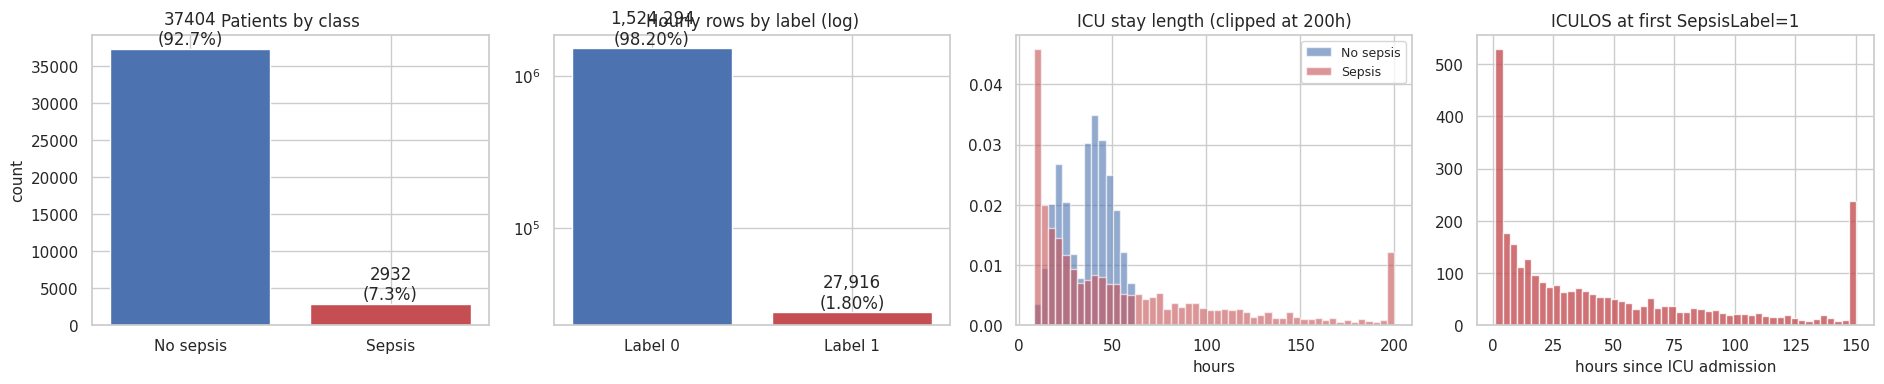

In [5]:
# ---- Figure 1 : équilibre des classes + durée de séjour + instant de début de l'étiquette ----
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
cnt = pat.ever_sepsis.value_counts().sort_index()
ax[0].bar(["No sepsis", "Sepsis"], cnt.values, color=["#4c72b0", "#c44e52"])
for i, v in enumerate(cnt.values): ax[0].text(i, v, f"{v}\n({100*v/cnt.sum():.1f}%)", ha="center", va="bottom")
ax[0].set_title("Patients by class"); ax[0].set_ylabel("count")

rc = df[TARGET].value_counts().sort_index()
ax[1].bar(["Label 0", "Label 1"], rc.values, color=["#4c72b0", "#c44e52"]); ax[1].set_yscale("log")
for i, v in enumerate(rc.values): ax[1].text(i, v, f"{v:,}\n({100*v/rc.sum():.2f}%)", ha="center", va="bottom")
ax[1].set_title("Hourly rows by label (log)")

for s, c in [(0, "#4c72b0"), (1, "#c44e52")]:
    ax[2].hist(pat.loc[pat.ever_sepsis == s, "n_hours"].clip(upper=200), bins=50, alpha=.6, color=c, density=True,
               label="Sepsis" if s else "No sepsis")
ax[2].set_title("ICU stay length (clipped at 200h)"); ax[2].set_xlabel("hours"); ax[2].legend()

t_on = df[df[TARGET] == 1].groupby("patient")["ICULOS"].min()
ax[3].hist(t_on.clip(upper=150), bins=50, color="#c44e52", alpha=.8)
ax[3].set_title("ICULOS at first SepsisLabel=1"); ax[3].set_xlabel("hours since ICU admission")
save_fig("F1_class_balance_and_lengths")

,Missing %,Type
Bilirubin_direct,99.81,lab
Fibrinogen,99.34,lab
TroponinI,99.05,lab
Bilirubin_total,98.51,lab
Alkalinephos,98.39,lab
AST,98.38,lab
Lactate,97.33,lab
PTT,97.06,lab
SaO2,96.55,lab
EtCO2,96.29,vital


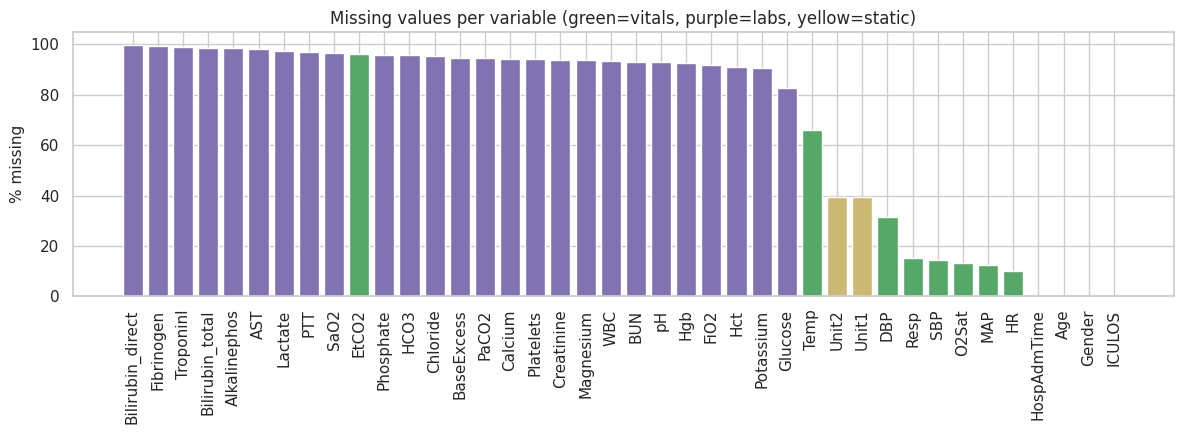

In [6]:
# ---- Tableau 2 + Figure 2 : pourcentage de valeurs manquantes ----
miss = (df[TIME_VARS + STATIC].isna().mean() * 100).sort_values(ascending=False).to_frame("Missing %")
miss["Type"] = ["vital" if i in VITALS else ("static" if i in STATIC else "lab") for i in miss.index]
save_table(miss, "T2_missingness", 2)

plt.figure(figsize=(12, 4.5))
cols = miss["Type"].map({"vital": "#55a868", "lab": "#8172b2", "static": "#ccb974"})
plt.bar(miss.index, miss["Missing %"], color=cols)
plt.xticks(rotation=90); plt.ylabel("% missing"); plt.title("Missing values per variable (green=vitals, purple=labs, yellow=static)")
save_fig("F2_missingness")

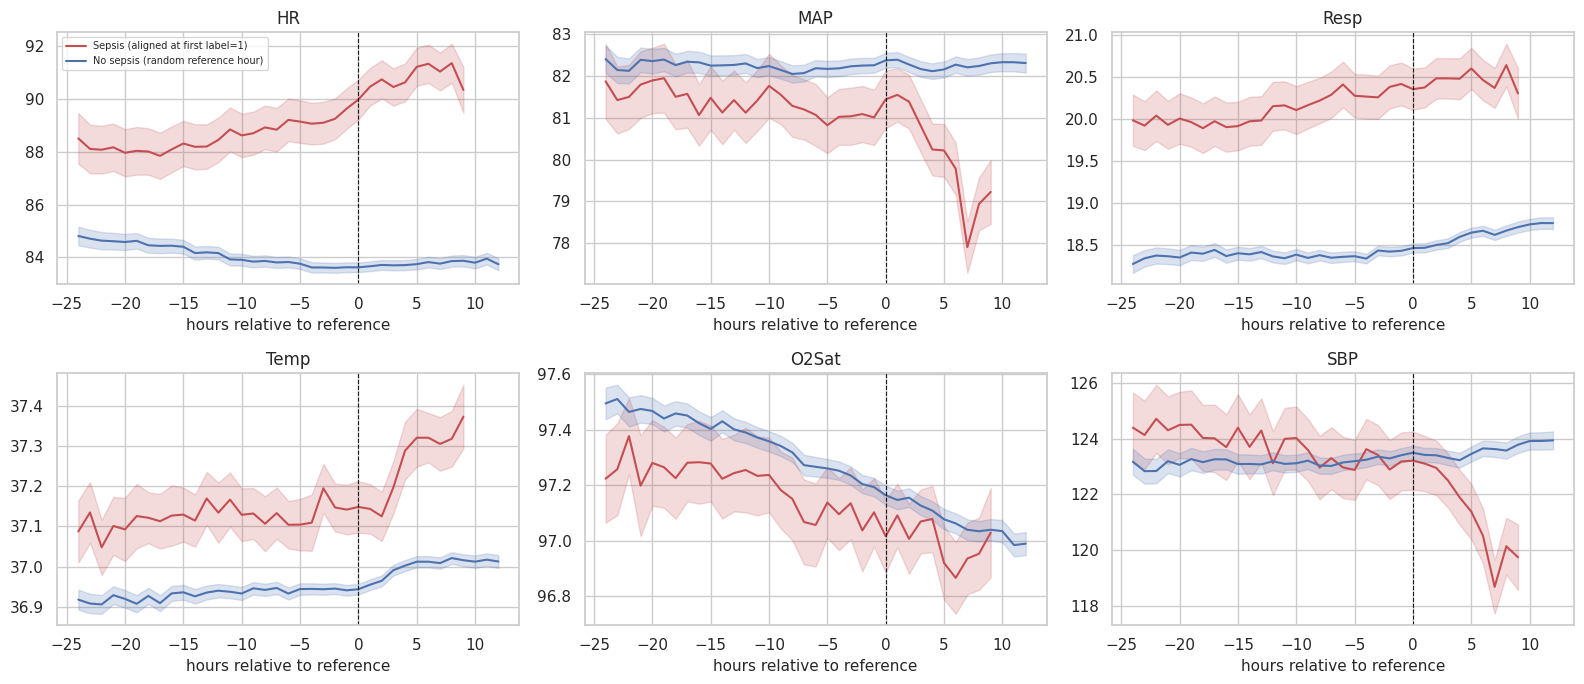

In [7]:
# ---- Figure 3 : trajectoires des signes vitaux autour du début de l'étiquette (Sepsis) vs patients sans sepsis ----
rng_al = np.random.default_rng(SEED)
t0_sep = df[df[TARGET] == 1].groupby("patient")["ICULOS"].min()
non_p = pat.index[pat.ever_sepsis == 0]
t0_non = df[df.patient.isin(non_p)].groupby("patient")["ICULOS"].apply(lambda s: rng_al.choice(s.values))   # instant de référence aléatoire
t0 = pd.concat([t0_sep, t0_non]).rename("t0")
tmp = df[["patient", "ICULOS"] + VITALS].join(t0, on="patient")
tmp["rel"] = (tmp["ICULOS"] - tmp["t0"]).astype(int)
tmp["cls"] = np.where(tmp["patient"].isin(t0_sep.index), "Sepsis (aligned at first label=1)", "No sepsis (random reference hour)")
tmp = tmp[(tmp.rel >= -24) & (tmp.rel <= 12)]

show = [v for v in ["HR", "MAP", "Resp", "Temp", "O2Sat", "SBP"] if v in VITALS]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for a, v in zip(axes.ravel(), show):
    g = tmp.groupby(["cls", "rel"])[v].agg(["mean", "sem"]).reset_index()
    for c, col in [("Sepsis (aligned at first label=1)", "#c44e52"), ("No sepsis (random reference hour)", "#4c72b0")]:
        gg = g[g.cls == c]
        a.plot(gg.rel, gg["mean"], color=col, label=c)
        a.fill_between(gg.rel, gg["mean"] - 1.96 * gg["sem"], gg["mean"] + 1.96 * gg["sem"], color=col, alpha=.2)
    a.axvline(0, color="k", ls="--", lw=.8); a.set_title(v); a.set_xlabel("hours relative to reference")
axes.ravel()[0].legend(loc="best", fontsize=7)
save_fig("F3_vitals_around_onset")

In [8]:
# ---- Tableau 3 : comparaison des variables principales entre les deux classes (moyenne par patient + Mann-Whitney) ----
key_vars = VITALS + [c for c in ["Lactate", "WBC", "Creatinine", "Platelets", "BUN", "Glucose"] if c in TIME_VARS] + ["Age", "ICULOS"]
pm = df.groupby("patient")[key_vars].mean().join(pat.ever_sepsis)
rows = []
for v in key_vars:
    a, b = pm.loc[pm.ever_sepsis == 0, v].dropna(), pm.loc[pm.ever_sepsis == 1, v].dropna()
    p = stats.mannwhitneyu(a, b).pvalue if len(a) > 5 and len(b) > 5 else np.nan
    q = lambda s: f"{s.median():.1f} [{s.quantile(.25):.1f}–{s.quantile(.75):.1f}]"
    rows.append({"Variable": v, "No sepsis: median [IQR]": q(a), "Sepsis: median [IQR]": q(b), "p-value": p})
tab3 = pd.DataFrame(rows).set_index("Variable")
save_table(tab3, "T3_class_comparison", 6)

,No sepsis: median [IQR],Sepsis: median [IQR],p-value
Variable,,,
HR,82.8 [73.2–92.6],88.4 [77.5–99.3],0.000000
O2Sat,97.4 [96.1–98.5],97.6 [96.1–98.8],0.000000
Temp,36.8 [36.5–37.2],37.0 [36.6–37.5],0.000000
SBP,121.4 [110.5–134.8],119.7 [107.9–132.7],0.000000
MAP,80.9 [73.7–90.2],79.3 [72.2–87.8],0.000000
DBP,63.0 [56.5–70.8],61.5 [55.1–68.9],0.000000
Resp,18.1 [16.4–20.2],19.2 [16.8–22.2],0.000000
EtCO2,33.2 [28.5–37.5],32.4 [27.7–36.3],0.002498
Lactate,1.7 [1.2–2.4],1.7 [1.2–2.6],0.166701


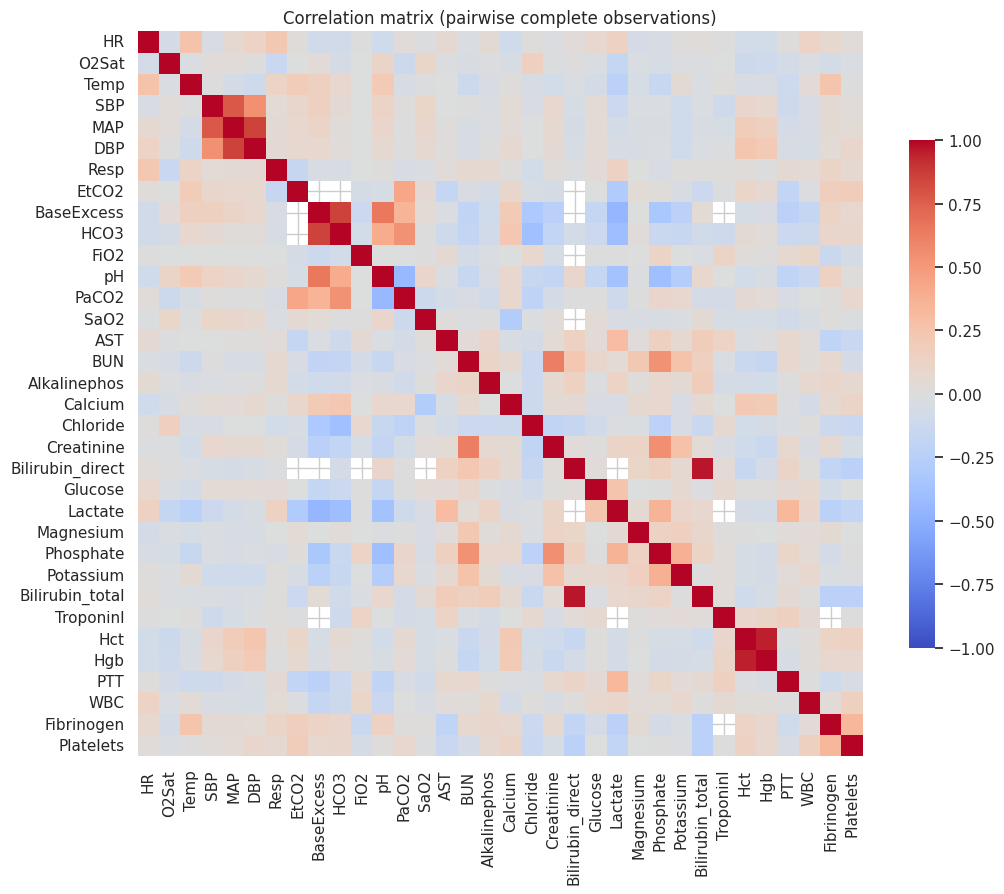

In [9]:
# ---- Figure 4 : matrice de corrélation entre les variables temporelles ----
cm = df[TIME_VARS].corr(min_periods=500)
plt.figure(figsize=(11, 9))
sns.heatmap(cm, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .7},
            xticklabels=True, yticklabels=True)
plt.title("Correlation matrix (pairwise complete observations)")
save_fig("F4_correlation")

## 3) Prétraitement (Preprocessing)

**Règles suivies (chacune évite une erreur courante) :**

1. **Séparation par patient (Patient-level split)** 70% / 15% / 15% avec stratification selon « a développé un sepsis ou non ». Si l'on séparait par lignes, un même patient apparaîtrait dans Train et dans Test (fuite de données).
2. **Forward-fill uniquement à l'intérieur de chaque patient** : valeur manquante = dernière mesure connue. C'est causal (n'utilise que le passé). On n'utilise jamais de backward-fill (il ferait fuiter le futur).
3. **Masques de mesure (Observation masks)** : pour chaque variable temporelle, une colonne $m_{t,j}\in\{0,1\}$ égale à 1 si la variable a **réellement été mesurée** à cette heure. La présence/absence de la mesure est elle-même une information clinique (le médecin demande un Lactate quand il soupçonne quelque chose).
4. **Normalisation (Z-score)** avec les statistiques de **Train uniquement** :
$$ \tilde x_{t,j}=\frac{x_{t,j}-\mu_j^{train}}{\sigma_j^{train}+\epsilon},\qquad \tilde x \leftarrow \operatorname{clip}(\tilde x,-5,5) $$
   puis les valeurs encore manquantes (variable jamais mesurée jusque-là) sont remplies par 0 (= la moyenne).  
   L'écrêtage à ±5 protège des valeurs aberrantes (les données contiennent des erreurs volontaires).
5. **Fenêtres temporelles glissantes** : pour chaque heure $t$, on construit une entrée $X_t\in\mathbb R^{T\times F}$ contenant les $T$ dernières heures (remplissage par des zéros au début du séjour), et la cible $y_t=\text{SepsisLabel}(t)$.  
   $T$ lui-même est un **paramètre recherché par DE** (6 … 24 heures).
6. **Fort déséquilibre (~2% de lignes positives)** : pendant l'entraînement, on prend toutes les lignes positives + un nouvel échantillon négatif à chaque epoch avec le ratio `neg_ratio:1`, et on utilise `pos_weight`. En revanche, **l'évaluation se fait sur la distribution naturelle** (sans rééquilibrage) afin que l'AUPRC soit réaliste.

In [10]:
# ---------- 3.1 Séparation des patients ----------
pids = np.array(pat.index.tolist())          # tableau NumPy classique (compatible avec les versions récentes de pandas/Arrow)
y_pat = pat.ever_sepsis.values.astype(int)
tr_p, tmp_p = train_test_split(pids, test_size=0.30, stratify=y_pat, random_state=SEED)
y_tmp = pat.loc[tmp_p, "ever_sepsis"].values.astype(int)
va_p, te_p = train_test_split(tmp_p, test_size=0.50, stratify=y_tmp, random_state=SEED)

split_of = pd.Series(0, index=pids); split_of.loc[va_p] = 1; split_of.loc[te_p] = 2
row_split = df["patient"].map(split_of).values                 # 0=train 1=val 2=test pour chaque ligne
assert len(set(tr_p) & set(va_p)) == 0 and len(set(tr_p) & set(te_p)) == 0 and len(set(va_p) & set(te_p)) == 0

tab_split = pd.DataFrame({
    "Patients": [len(tr_p), len(va_p), len(te_p)],
    "Sepsis patients": [int(pat.loc[p, "ever_sepsis"].sum()) for p in (tr_p, va_p, te_p)],
    "Rows": [int((row_split == k).sum()) for k in range(3)],
    "Positive rows": [int(df[TARGET].values[row_split == k].sum()) for k in range(3)]},
    index=["Train", "Validation", "Test"])
tab_split["Positive % (rows)"] = 100 * tab_split["Positive rows"] / tab_split["Rows"]
save_table(tab_split, "T4_split_summary")

,Patients,Sepsis patients,Rows,Positive rows,Positive % (rows)
Train,28235,2052,1086436,19560,1.8004
Validation,6050,440,231472,4162,1.7981
Test,6051,440,234302,4194,1.7900


In [11]:
# ---------- 3.2 ffill + masques + normalisation (statistiques de Train uniquement) ----------
M = df[TIME_VARS].notna().astype("float32").values                      # masques de mesure (avant le ffill)
df[TIME_VARS] = df.groupby("patient")[TIME_VARS].ffill()                # ffill causal à l'intérieur du patient

FEAT = TIME_VARS + STATIC
X = df[FEAT].values.astype("float32")
tr_mask = row_split == 0
mu = np.nanmean(X[tr_mask], axis=0)
sd = np.nanstd(X[tr_mask], axis=0)
X = (X - mu) / (sd + 1e-6)
X = np.clip(X, -5, 5)
X = np.nan_to_num(X, nan=0.0).astype("float32")
# [FIX] temps écoulé depuis la dernière mesure de chaque variable (causal), compressé en log et plafonné à 48h
_it = df["ICULOS"].values[:, None]
_last = pd.DataFrame(np.where(M > 0, _it, np.nan), columns=TIME_VARS)
_last["patient"] = df["patient"].values
_last = _last.groupby("patient")[TIME_VARS].ffill().values
DT = np.where(np.isnan(_last), 48.0, np.minimum(_it - _last, 48.0)).astype("float32")
DT = (np.log1p(DT) / np.log1p(48.0)).astype("float32")
X = np.concatenate([X, M, DT], axis=1)                                      # [valeurs normalisées | masques de mesure]
FEATURE_NAMES = FEAT + [f"{c}_obs" for c in TIME_VARS] + [f"{c}_dt" for c in TIME_VARS]
N_FEAT = X.shape[1]

y_all = df[TARGET].values.astype("float32")
it_all = df["ICULOS"].values
pcode = pd.factorize(df["patient"])[0]
print("Forme de la matrice de features :", X.shape, "| nombre de features :", N_FEAT)

# ---------- 3.3 Matrice ordonnée (Padded) pour construire rapidement les fenêtres ----------
# Chaque patient est précédé de (WMAX-1) lignes de zéros => la fenêtre de la ligne r est simplement XPAD[pos[r]-T+1 : pos[r]+1]
n_pat = pcode.max() + 1
POS = (np.arange(len(X)) + (pcode + 1) * (WMAX - 1)).astype("int64")
XPAD = np.zeros((len(X) + n_pat * (WMAX - 1), N_FEAT), dtype="float32")
XPAD[POS] = X
print(f"XPAD: {XPAD.shape} ≈ {XPAD.nbytes/1e6:.0f} MB")

XPAD_t = torch.from_numpy(XPAD).to(DEVICE)
POS_t  = torch.from_numpy(POS).to(DEVICE)
Y_t    = torch.from_numpy(y_all).to(DEVICE)
AR_t   = torch.arange(WMAX, device=DEVICE)

def make_batch(rows, T):
    """rows: tensor long (B,) d'identifiants globaux de lignes → fenêtres (B,T,F), étiquettes (B,)"""
    p = POS_t[rows]
    idx = p[:, None] - (T - 1) + AR_t[None, :T]
    return XPAD_t[idx], Y_t[rows]

# ---------- 3.4 Ensembles de lignes ----------
rs = np.random.default_rng(SEED)
tr_rows = np.where(row_split == 0)[0]
va_rows_all = np.where(row_split == 1)[0]
te_rows = np.where(row_split == 2)[0]

TRAIN_POS = torch.from_numpy(tr_rows[y_all[tr_rows] == 1]).to(DEVICE)
TRAIN_NEG = torch.from_numpy(tr_rows[y_all[tr_rows] == 0]).to(DEVICE)

nva = min(CFG["val_rows"], len(va_rows_all))
va_rows = np.sort(rs.choice(va_rows_all, nva, replace=False))            # échantillon de Validation avec la prévalence naturelle
VAL_ROWS_t  = torch.from_numpy(va_rows).to(DEVICE)
TEST_ROWS_t = torch.from_numpy(te_rows).to(DEVICE)
print(f"Train: pos={len(TRAIN_POS):,} neg={len(TRAIN_NEG):,} | Val(échantillon): {len(va_rows):,} (pos={int(y_all[va_rows].sum())}) | Test: {len(te_rows):,} (pos={int(y_all[te_rows].sum())})")
assert y_all[va_rows].sum() > 0, "L'échantillon de Validation n'a aucun cas positif : augmentez val_rows"

Forme de la matrice de features : (1552210, 108) | nombre de features : 108
XPAD: (2802626, 108) ≈ 1211 MB
Train: pos=19,560 neg=1,066,876 | Val(échantillon): 80,000 (pos=1458) | Test: 234,302 (pos=4194)


## 4) Le modèle : LSTM et équations

Pour chaque pas de temps $t$ avec l'entrée $x_t\in\mathbb R^{F}$, l'état caché $h_{t-1}$ et l'état de cellule $c_{t-1}$ :

$$
\begin{aligned}
i_t &= \sigma\!\left(W_i x_t + U_i h_{t-1} + b_i\right) &&\text{(porte d'entrée : quelle quantité écrire en mémoire)}\\
f_t &= \sigma\!\left(W_f x_t + U_f h_{t-1} + b_f\right) &&\text{(porte d'oubli : quelle part du passé conserver)}\\
g_t &= \tanh\!\left(W_g x_t + U_g h_{t-1} + b_g\right) &&\text{(contenu candidat)}\\
o_t &= \sigma\!\left(W_o x_t + U_o h_{t-1} + b_o\right) &&\text{(porte de sortie)}\\
c_t &= f_t \odot c_{t-1} + i_t \odot g_t &&\text{(mise à jour de la mémoire à long terme)}\\
h_t &= o_t \odot \tanh(c_t) &&\text{(état caché)}
\end{aligned}
$$

où $\sigma(z)=\frac{1}{1+e^{-z}}$ et $\odot$ est le produit élément par élément. La somme $c_t=f_t\odot c_{t-1}+\dots$ est la raison pour laquelle le LSTM évite la disparition du gradient (vanishing gradient) par rapport à un RNN classique.

**Tête de classification :** on prend le dernier état caché $h_T$ (de la dernière couche) puis :
$$ z = W_2\,\mathrm{ReLU}(W_1\,\mathrm{Dropout}(h_T)+b_1)+b_2,\qquad \hat p=\sigma(z) $$

**Fonction de perte (Weighted BCE)** pour traiter le déséquilibre :
$$ \mathcal L=-\frac1N\sum_{n=1}^{N}\Big[\,w_{+}\,y_n\log\hat p_n+(1-y_n)\log(1-\hat p_n)\Big],\qquad w_+=\big(\tfrac{N_-}{N_+}\big)^{0.5} $$

**Optimiseur :** AdamW (Adam avec weight-decay découplé $\lambda$) + écrêtage du gradient (gradient clipping) à 1.0.

**Que va rechercher DE ?** (espace de recherche à 6 dimensions, mixte : entiers + réels + logarithmiques)

| Paramètre | Intervalle | Encodage |
|---|---|---|
| `hidden` (taille de l'état caché) | 16 … 128 | entier (floor) |
| `layers` (nombre de couches LSTM) | 1 … 3 | entier (floor) |
| `dropout` | 0 … 0.5 | réel |
| `lr` (taux d'apprentissage) | $10^{-5}$ … $10^{-2}$ | recherché en $\log_{10}$ |
| `wd` (weight decay) | $10^{-6}$ … $10^{-2}$ | recherché en $\log_{10}$ |
| `window` $T$ (heures) | 6 … 32 | entier (floor) |

Pourquoi le logarithme ? Parce que l'effet de lr entre $10^{-5}$ et $10^{-4}$ ressemble à son effet entre $10^{-3}$ et $10^{-2}$ ; une recherche linéaire négligerait donc la petite plage.

In [12]:
class SepsisLSTM(nn.Module):
    def __init__(self, n_feat, hidden, layers, dropout):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, num_layers=layers, batch_first=True,
                            dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden, max(hidden // 2, 8))
        self.fc2 = nn.Linear(max(hidden // 2, 8), 1)

    def forward(self, x):
        out, _ = self.lstm(x)              # (B,T,H)
        h = self.drop(out[:, -1, :])       # dernier pas de temps
        return self.fc2(torch.relu(self.fc1(h))).squeeze(-1)

@torch.no_grad()
def predict_proba(model, rows_t, T, bs=2048):
    model.eval(); out = []
    for i in range(0, len(rows_t), bs):
        xb, _ = make_batch(rows_t[i:i + bs], T)
        out.append(torch.sigmoid(model(xb)).float().cpu())
    return torch.cat(out).numpy()

def train_model(hp, epochs, seed, neg_ratio, patience=None, return_model=False):
    """Entraîne un LSTM et renvoie la meilleure AUPRC sur Validation (meilleur epoch)."""
    t_start = time.time(); set_seed(seed)
    T = hp["window"]
    model = SepsisLSTM(N_FEAT, hp["hidden"], hp["layers"], hp["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"])
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(neg_ratio) ** POS_W_POWER, device=DEVICE))
    g = torch.Generator().manual_seed(seed)
    y_val = y_all[va_rows]
    n_pos_ep = max(int(len(TRAIN_POS) * EP_FRAC), 1); n_neg = min(int(n_pos_ep * neg_ratio), len(TRAIN_NEG))
    hist = []; best = dict(ap=-1, epoch=-1, state=None); bad = 0

    for ep in range(epochs):
        model.train()
        neg_s = TRAIN_NEG[torch.randperm(len(TRAIN_NEG), generator=g)[:n_neg].to(DEVICE)]   # nouvel échantillon négatif à chaque epoch
        pos_s = TRAIN_POS[torch.randperm(len(TRAIN_POS), generator=g)[:n_pos_ep].to(DEVICE)]
        rows = torch.cat([pos_s, neg_s])
        rows = rows[torch.randperm(len(rows), generator=g).to(DEVICE)]
        tot, cnt = 0.0, 0
        for i in range(0, len(rows), BATCH):
            xb, yb = make_batch(rows[i:i + BATCH], T)
            if INPUT_NOISE > 0: xb = xb + INPUT_NOISE * torch.randn_like(xb)
            loss = crit(model(xb), yb)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += loss.item() * len(yb); cnt += len(yb)
        pv = predict_proba(model, VAL_ROWS_t, T)
        ap = average_precision_score(y_val, pv); auc = roc_auc_score(y_val, pv)
        hist.append(dict(epoch=ep + 1, train_loss=tot / cnt, val_auprc=ap, val_auroc=auc))
        if ap > best["ap"]:
            best.update(ap=ap, epoch=ep + 1, state={k: v.detach().clone() for k, v in model.state_dict().items()}); bad = 0
        else:
            bad += 1
            if patience and bad >= patience: break

    model.load_state_dict(best["state"])
    res = dict(best_ap=float(best["ap"]), best_epoch=best["epoch"], history=pd.DataFrame(hist),
               time_s=time.time() - t_start, n_params=sum(p.numel() for p in model.parameters()))
    if return_model: res["model"] = model
    else: del model, opt
    return res

# Test rapide pour vérifier que tout fonctionne (un seul epoch, petit modèle)
_t = train_model(dict(hidden=16, layers=1, dropout=0.1, lr=1e-3, wd=1e-5, window=8), epochs=1, seed=0, neg_ratio=CFG["neg_ratio"])
print(f"smoke test: val AUPRC={_t['best_ap']:.4f} | {_t['time_s']:.1f}s par évaluation environ → budget total de recherche ≈ {_t['time_s']*CFG['epochs_search']*CFG['obj_seeds']*2*CFG['de_pop']*(CFG['de_gen']+1)/60:.0f} minutes (estimation approximative)")

smoke test: val AUPRC=0.0681 | 1.1s par évaluation environ → budget total de recherche ≈ 156 minutes (estimation approximative)


## 5) Évolution Différentielle (DE) — Explication détaillée

### 5.1 Qu'est-ce que DE et pourquoi l'utiliser ici ?
**Differential Evolution** est une méta-heuristique évolutionnaire proposée par Storn & Price (1995–1997). C'est une **recherche globale (Global)** fondée sur une **population** de solutions candidates, qui n'a pas besoin de **gradient** (gradient-free).  
Objectif : trouver
$$ x^\star=\arg\min_{x\in\Omega} f(x),\qquad \Omega=\prod_{j=1}^{D}[\ell_j,u_j] $$
Dans notre cas $f(x)=1-\text{AUPRC}_{val}\big(\text{LSTM}(\mathrm{hp}(x))\big)$.

**Pourquoi ne pas utiliser la descente de gradient sur les hyperparamètres ?** Parce que $f$ est ici une **boîte noire (black-box)** : non dérivable (nombre de couches/taille cachée sont des entiers), **coûteuse** (chaque évaluation = entraînement d'un réseau), **bruitée** (seed, mini-batch) et possiblement **non convexe** avec de nombreux optima locaux.  
DE convient car : (1) elle n'a pas besoin de dérivées, (2) elle n'a que 3 paramètres de contrôle ($NP, F, CR$), (3) elle est robuste sur les problèmes non linéaires/multimodaux, (4) elle est parallélisable (l'évaluation des enfants est indépendante), (5) la **sélection gloutonne (greedy)** garantit que la meilleure valeur ne se dégrade jamais.

### 5.2 L'algorithme pas à pas
La population à la génération $g$ : $P_g=\{x_1^g,\dots,x_{NP}^g\}$, avec chaque $x_i^g\in\mathbb R^D$.

**(a) Initialisation (Initialization)**
$$ x_{i,j}^{0}=\ell_j+r_{ij}\,(u_j-\ell_j),\quad r_{ij}\sim U(0,1) $$
On utilise aussi l'**échantillonnage par hypercube latin (Latin Hypercube Sampling, LHS)** : on divise chaque dimension en $NP$ tranches égales et on prend un point par tranche dans un ordre aléatoire ⇒ couverture plus régulière que l'aléatoire pur (important quand $NP$ est petit).

**(b) Mutation — création du vecteur donneur (Donor) $v_i$**  
Le cœur distinctif de DE : on ajoute une **différence pondérée entre deux individus** à un troisième individu.

| Stratégie | Équation | Caractère |
|---|---|---|
| `rand/1` | $v_i=x_{r_1}+F\,(x_{r_2}-x_{r_3})$ | forte exploration, convergence plus lente, la plus robuste |
| `best/1` | $v_i=x_{best}+F\,(x_{r_1}-x_{r_2})$ | forte exploitation, convergence rapide, risque d'optima locaux |
| `rand/2` | $v_i=x_{r_1}+F(x_{r_2}-x_{r_3})+F(x_{r_4}-x_{r_5})$ | plus d'exploration (nécessite $NP\ge 6$) |
| `best/2` | $v_i=x_{best}+F(x_{r_1}-x_{r_2})+F(x_{r_3}-x_{r_4})$ | exploitation + plus de diversité |
| `current-to-best/1` | $v_i=x_i+F\,(x_{best}-x_i)+F\,(x_{r_1}-x_{r_2})$ | équilibre : se déplace vers le meilleur avec un bruit différentiel |

où $r_1\neq r_2\neq r_3\neq\dots\neq i$ sont des indices aléatoires distincts, et $F\in(0,1]$ (parfois jusqu'à 2) est le **facteur d'amplification/taille de pas**.

> **Pourquoi une « différence » entre deux individus ?** L'amplitude de la différence $\lVert x_{r_2}-x_{r_3}\rVert$ est proportionnelle à la **dispersion de la population**. Au début (population dispersée) les pas sont grands ⇒ exploration. À mesure que la population converge, les pas diminuent **automatiquement** ⇒ exploitation fine. Autrement dit, DE possède un « programme de refroidissement » auto-adaptatif sans qu'on le programme (contrairement au Simulated Annealing).

**(c) Gestion des bornes (Bound handling)** si une composante sort de $[\ell_j,u_j]$ (on travaille en interne dans le cube $[0,1]^D$) :
- `clip` : $v\leftarrow\min(\max(v,0),1)$ (accumule des points sur les bords).
- `reflect` : $v\leftarrow -v$ si $v<0$, et $v\leftarrow 2-v$ si $v>1$ (utilisé par défaut).
- `random` : on retire aléatoirement la composante.

**(d) Croisement (Crossover) binomial — création du vecteur d'essai (Trial) $u_i$**
$$
u_{i,j}=\begin{cases} v_{i,j} & \text{si } r_{ij}\le CR\ \ \text{ou}\ \ j=j_{rand}\\ x_{i,j} & \text{sinon}\end{cases}
$$
- $CR\in[0,1]$ est la **probabilité de prendre la composante du donneur** ; le nombre attendu de composantes prises dans $v_i$ est $1+CR\,(D-1)$.
- L'indice aléatoire $j_{rand}$ garantit qu'**au moins une composante** vient du donneur (sinon on obtient une copie du parent et on gaspille une évaluation).
- $CR$ petit ⇒ recherche quasi séparée par coordonnées (adaptée aux fonctions séparables), $CR$ grand ⇒ déplacement simultané dans toutes les dimensions (adapté aux variables corrélées, comme les paramètres des réseaux de neurones).

**(e) Sélection (Selection) gloutonne/élitiste**
$$
x_i^{g+1}=\begin{cases}u_i & \text{si } f(u_i)\le f(x_i^{g})\\ x_i^{g} & \text{sinon}\end{cases}
$$
L'enfant ne remplace que **son parent direct** (pas le pire individu) ⇒ préserve la diversité et empêche la convergence prématurée ; et comme le remplacement n'a lieu qu'en cas d'amélioration, $\min_i f(x_i^g)$ est **non croissante** au fil des générations.

**(f) Critère d'arrêt :** nombre de générations $G$ (budget fixe) ⇒ nombre total d'évaluations
$$ N_{eval}=NP\cdot(G+1) $$

### 5.3 Pseudo-code
```
P ← Init(NP)                 # LHS dans [0,1]^D
f ← Eval(P)                  # NP évaluations
for g = 1..G:
    for each i in 1..NP:
        v_i ← Mutate(P, i, F, strategy)
        v_i ← Repair(v_i)
        u_i ← Crossover(P_i, v_i, CR)          # avec j_rand
    f_u ← Eval({u_i})                          # parallélisable
    for each i:  if f_u[i] ≤ f[i]:  P_i, f[i] ← u_i, f_u[i]
return argmin f
```

### 5.4 Mini-exemple numérique (D=2, fonction Sphere $f=x_1^2+x_2^2$)
Le parent $x_i=(5,2)$ et $x_{r_1}=(2,3),\ x_{r_2}=(4,1),\ x_{r_3}=(1,5)$ avec $F=0.5$, $CR=0.8$ :
1. **Mutation rand/1 :** $v=(2,3)+0.5\cdot\big((4,1)-(1,5)\big)=(2,3)+0.5\cdot(3,-4)=(3.5,\;1)$
2. **Croisement :** supposons $r_{i1}=0.3\le CR$ ⇒ $u_1=v_1=3.5$ ; et $r_{i2}=0.9>CR$ et $j_{rand}=1$ ⇒ $u_2=x_{i,2}=2$ ⇒ $u=(3.5,\,2)$
3. **Sélection :** $f(x_i)=25+4=29$ et $f(u)=12.25+4=16.25\le29$ ⇒ **l'enfant est accepté** et remplace le parent.

### 5.5 Les trois paramètres et règles pratiques de réglage
| Paramètre | Signification | Valeurs courantes | Effet |
|---|---|---|---|
| $NP$ | taille de la population | $5D\!-\!10D$ (et $\approx 2D\!-\!4D$ quand l'évaluation est très coûteuse) | plus grand ⇒ meilleure exploration mais budget plus important |
| $F$ | taille du pas de mutation | 0.4 – 0.9 (défaut 0.5–0.6) | grand ⇒ exploration, petit ⇒ convergence prématurée |
| $CR$ | probabilité de croisement | 0.1 – 0.9 (fonctions corrélées 0.8–0.95) | grand ⇒ plus de coordonnées modifiées simultanément |

**jDE (Brest et al., 2006) — DE auto-adaptative :** chaque individu porte ses propres $F_i, CR_i$, régénérés avant chaque mutation avec la probabilité $\tau_1=\tau_2=0.1$ :
$$ F_i^{g+1}=\begin{cases}F_l+r_1F_u & r_2<\tau_1\\ F_i^{g}&\text{sinon}\end{cases}\qquad CR_i^{g+1}=\begin{cases}r_3 & r_4<\tau_2\\ CR_i^{g}&\text{sinon}\end{cases} $$
et les valeurs ne sont conservées que si l'enfant réussit la sélection ⇒ les réglages réussis « se transmettent » avec les bonnes solutions.

### 5.6 Indicateurs de diagnostic de DE que nous allons tracer
- **Meilleure/moyenne/pire valeur** de la fonction à chaque génération (convergence).
- **Diversité (Diversity)** : $\displaystyle \mathcal D_g=\frac1D\sum_{j=1}^{D}\operatorname{std}_i\big(\tilde x^{g}_{i,j}\big)$ sur le cube unité $[0,1]^D$. Elle diminue avec la convergence ; une chute trop rapide = convergence prématurée.
- **Taux de succès (Success rate) :** $SR_g=\frac{1}{NP}\big|\{i:\ f(u_i)\le f(x_i)\}\big|$. S'il tend vers 0, la recherche est bloquée ; s'il reste élevé, il y a encore une marge d'amélioration.
- **Trajectoires des paramètres (Parameter trajectories) :** comment la plage de chaque hyperparamètre se contracte au fil des générations.

### 5.7 Encodage des paramètres entiers et logarithmiques
DE travaille dans un espace **réel**, nous décodons donc à l'intérieur de la fonction objectif : `hidden = floor(x₀)` sur l'intervalle $[16,129)$ pour que chaque entier ait une chance égale, et `lr = 10^{x₃}` avec $x_3\in[-4,-2]$. Inconvénient : des zones plates (des valeurs différentes de x donnent le même hp) — nous utilisons donc un **cache** pour éviter de ré-entraîner.

In [13]:
# ==================== Implémentation de DE de zéro (réutilisable) ====================
class DifferentialEvolution:
    """
    Differential Evolution (Storn & Price) — vectorisée et synchrone.
    - Travaille en interne dans le cube [0,1]^D et décode vers [lo,hi] avant d'appeler la fonction.
    - strategies: rand1bin, best1bin, rand2bin, best2bin, currenttobest1bin
    - adaptive=True  ⇒ jDE (F et CR par individu)
    - vectorized=True ⇒ func reçoit une matrice (NP,D) et renvoie (NP,)  (pour les fonctions de référence rapides)
    """
    MIN_NP = {"rand1bin": 4, "best1bin": 3, "rand2bin": 6, "best2bin": 5, "currenttobest1bin": 4}

    def __init__(self, func, bounds, pop_size=20, F=0.6, CR=0.9, strategy="rand1bin", max_gen=50,
                 init="lhs", bound_handling="reflect", adaptive=False, tau1=0.1, tau2=0.1,
                 F_bounds=(0.1, 0.9), vectorized=False, seed=0, verbose=False, callback=None):
        assert strategy in self.MIN_NP, f"strategy must be in {list(self.MIN_NP)}"
        assert pop_size >= self.MIN_NP[strategy], f"pop_size >= {self.MIN_NP[strategy]} pour cette stratégie"
        self.func, self.NP, self.F, self.CR, self.strategy, self.max_gen = func, int(pop_size), F, CR, strategy, int(max_gen)
        b = np.asarray(bounds, float); self.lo, self.hi, self.D = b[:, 0], b[:, 1], len(b)
        self.init, self.bound_handling, self.adaptive = init, bound_handling, adaptive
        self.tau1, self.tau2, self.F_bounds = tau1, tau2, F_bounds
        self.vectorized, self.verbose, self.callback = vectorized, verbose, callback
        self.rng = np.random.default_rng(seed)
        self.n_evals = 0; self.history = []; self.pop_hist = []; self.fit_hist = []
        self.best_x_hist = []; self.eval_f = []; self.eval_gen = []; self.eval_acc = []

    # ---------- Outils ----------
    def _decode(self, U): return self.lo + U * (self.hi - self.lo)

    def _evaluate(self, U):
        X = self._decode(U)
        f = np.asarray(self.func(X), float) if self.vectorized else np.array([self.func(x) for x in X], float)
        f = np.where(np.isfinite(f), f, 1e12)
        self.n_evals += len(U)
        return f

    def _init_pop(self):
        if self.init == "lhs":
            U = np.empty((self.NP, self.D))
            for j in range(self.D):
                U[:, j] = (self.rng.permutation(self.NP) + self.rng.random(self.NP)) / self.NP
            return U
        return self.rng.random((self.NP, self.D))

    def _pick(self, k):
        """k indices distincts pour chaque individu i, tous ≠ i"""
        R = self.rng.random((self.NP, self.NP)); np.fill_diagonal(R, np.inf)
        return np.argsort(R, axis=1)[:, :k]

    def _mutate(self, U, f, Fv):
        best = U[np.argmin(f)]; Fc = Fv[:, None]; s = self.strategy
        if s == "rand1bin":
            r = self._pick(3); return U[r[:, 0]] + Fc * (U[r[:, 1]] - U[r[:, 2]])
        if s == "best1bin":
            r = self._pick(2); return best + Fc * (U[r[:, 0]] - U[r[:, 1]])
        if s == "rand2bin":
            r = self._pick(5); return U[r[:, 0]] + Fc * (U[r[:, 1]] - U[r[:, 2]]) + Fc * (U[r[:, 3]] - U[r[:, 4]])
        if s == "best2bin":
            r = self._pick(4); return best + Fc * (U[r[:, 0]] - U[r[:, 1]]) + Fc * (U[r[:, 2]] - U[r[:, 3]])
        r = self._pick(2)      # currenttobest1bin
        return U + Fc * (best - U) + Fc * (U[r[:, 0]] - U[r[:, 1]])

    def _repair(self, V):
        if self.bound_handling == "clip": return np.clip(V, 0, 1)
        if self.bound_handling == "random":
            return np.where((V < 0) | (V > 1), self.rng.random(V.shape), V)
        V = np.where(V < 0, -V, V); V = np.where(V > 1, 2 - V, V)       # reflect
        return np.clip(V, 0, 1)

    def _crossover(self, U, V, CRv):
        mask = self.rng.random((self.NP, self.D)) <= CRv[:, None]
        mask[np.arange(self.NP), self.rng.integers(0, self.D, self.NP)] = True    # j_rand
        return np.where(mask, V, U)

    def _record(self, g, U, f, sr, Fv, CRv):
        self.history.append(dict(gen=g, n_evals=self.n_evals, best_f=f.min(), mean_f=f.mean(), median_f=np.median(f),
                                 worst_f=f.max(), std_f=f.std(), diversity=U.std(axis=0).mean(),
                                 success_rate=sr, mean_F=Fv.mean(), mean_CR=CRv.mean()))
        self.best_x_hist.append(self._decode(U[np.argmin(f)]).copy())
        self.pop_hist.append(self._decode(U).copy()); self.fit_hist.append(f.copy())
        if self.verbose:
            h = self.history[-1]
            print(f"gen {g:3d} | evals {h['n_evals']:5d} | best {h['best_f']:.5g} | mean {h['mean_f']:.5g} | div {h['diversity']:.3f} | SR {h['success_rate']:.2f}")
        if self.callback: self.callback(self, g)

    # ---------- Exécution ----------
    def run(self):
        NP = self.NP
        U = self._init_pop(); f = self._evaluate(U)
        Fv = np.full(NP, 0.5 if self.adaptive else self.F); CRv = np.full(NP, 0.9 if self.adaptive else self.CR)
        self.eval_f += list(f); self.eval_gen += [0] * NP; self.eval_acc += [True] * NP
        self._record(0, U, f, np.nan, Fv, CRv)
        for g in range(1, self.max_gen + 1):
            if self.adaptive:                                          # jDE
                Ft = np.where(self.rng.random(NP) < self.tau1, self.F_bounds[0] + self.rng.random(NP) * self.F_bounds[1], Fv)
                CRt = np.where(self.rng.random(NP) < self.tau2, self.rng.random(NP), CRv)
            else:
                Ft, CRt = Fv, CRv
            V = self._repair(self._mutate(U, f, Ft))
            T = self._crossover(U, V, CRt)
            ft = self._evaluate(T)
            acc = ft <= f                                              # sélection gloutonne
            U[acc] = T[acc]; f[acc] = ft[acc]
            if self.adaptive: Fv, CRv = np.where(acc, Ft, Fv), np.where(acc, CRt, CRv)
            self.eval_f += list(ft); self.eval_gen += [g] * NP; self.eval_acc += list(acc)
            self._record(g, U, f, acc.mean(), Fv, CRv)
        i = int(np.argmin(f)); self.best_f, self.best_x = float(f[i]), self._decode(U[i])
        self.history_df = pd.DataFrame(self.history)
        return self

# Test rapide sur Sphere
_t = DifferentialEvolution(lambda X: (X ** 2).sum(1), [(-5, 5)] * 5, pop_size=20, max_gen=60, vectorized=True, seed=1).run()
print(f"DE sanity check sur Sphere(5D): best_f = {_t.best_f:.3e} après {_t.n_evals} évaluations")

DE sanity check sur Sphere(5D): best_f = 2.271e-04 après 1220 évaluations


## 6) Test de la robustesse de DE sur des fonctions de référence (Benchmarks)

Avant d'appliquer DE au LSTM (où le bruit et le coût élevé brouillent l'image), nous la testons sur 4 fonctions connues (D=10) aux propriétés différentes, **avec un décalage aléatoire de l'optimum** pour que DE ne profite pas de sa position au centre de l'espace :

| Fonction | Propriété | Équation |
|---|---|---|
| Sphere | convexe, facile, séparable | $\sum x_j^2$ |
| Rosenbrock | vallée étroite et courbe, variables corrélées | $\sum 100(x_{j+1}-x_j^2)^2+(1-x_j)^2$ |
| Rastrigin | **nombre énorme d'optima locaux** | $10D+\sum x_j^2-10\cos(2\pi x_j)$ |
| Ackley | surface quasi plate + trou étroit à la solution | $-20e^{-0.2\sqrt{\tfrac1D\sum x_j^2}}-e^{\tfrac1D\sum\cos 2\pi x_j}+20+e$ |

**Comparaison :** 5 variantes de DE contre **Random Search** avec le même budget d'évaluations (≈15 mille évaluations), en répétant l'expérience plusieurs fois (seeds différentes) pour obtenir moyenne et écart-type.

In [14]:
def make_bench(name, D=10, seed=123):
    r = np.random.default_rng(seed)
    lim = {"Sphere": 5.12, "Rastrigin": 5.12, "Rosenbrock": 2.048, "Ackley": 32.768}[name]
    shift = r.uniform(-0.4 * lim, 0.4 * lim, D)                       # décalage de l'optimum
    def f(X):
        X = np.atleast_2d(X); Z = X - shift
        if name == "Sphere":     return (Z ** 2).sum(1)
        if name == "Rastrigin":  return 10 * D + (Z ** 2 - 10 * np.cos(2 * np.pi * Z)).sum(1)
        if name == "Rosenbrock": Z = Z + 1; return (100 * (Z[:, 1:] - Z[:, :-1] ** 2) ** 2 + (1 - Z[:, :-1]) ** 2).sum(1)
        d = Z.shape[1]
        return (-20 * np.exp(-0.2 * np.sqrt((Z ** 2).sum(1) / d)) - np.exp(np.cos(2 * np.pi * Z).sum(1) / d) + 20 + np.e)
    return f, [(-lim, lim)] * D, shift

BENCH_FUNCS = ["Sphere", "Rosenbrock", "Rastrigin", "Ackley"]
BENCH_METHODS = {
    "DE rand/1/bin":        dict(strategy="rand1bin", F=0.5, CR=0.9),
    "DE best/1/bin":        dict(strategy="best1bin", F=0.5, CR=0.9),
    "DE rand/2/bin":        dict(strategy="rand2bin", F=0.5, CR=0.9),
    "DE current-to-best/1": dict(strategy="currenttobest1bin", F=0.5, CR=0.9),
    "jDE (adaptive)":       dict(strategy="rand1bin", adaptive=True),
}
NP_B, G_B, RUNS_B = 50, 300, CFG["bench_runs"]
curves = {fn: {} for fn in BENCH_FUNCS}      # [func][method] -> (runs, G+1) meilleure valeur au fil des générations
finals = []

for fn in BENCH_FUNCS:
    f, bnd, _ = make_bench(fn)
    for m, kw in BENCH_METHODS.items():
        C = []
        for r in range(RUNS_B):
            de_b = DifferentialEvolution(f, bnd, pop_size=NP_B, max_gen=G_B, vectorized=True, seed=1000 + r, **kw).run()
            C.append(de_b.history_df.best_f.values)
        curves[fn][m] = np.array(C)
    # Random search avec le même budget
    n_ev = NP_B * (G_B + 1); lo, hi = np.array(bnd)[:, 0], np.array(bnd)[:, 1]
    C = []
    for r in range(RUNS_B):
        S = np.random.default_rng(2000 + r).uniform(lo, hi, size=(n_ev, len(bnd)))
        C.append(np.minimum.accumulate(f(S))[np.arange(G_B + 1) * NP_B + NP_B - 1])
    curves[fn]["Random Search"] = np.array(C)
    for m, A in curves[fn].items():
        for v in A[:, -1]: finals.append(dict(Function=fn, Method=m, final_f=v))
print("Expériences sur les fonctions de référence terminées :", {fn: list(curves[fn]) for fn in BENCH_FUNCS[:1]})

Expériences sur les fonctions de référence terminées : {'Sphere': ['DE rand/1/bin', 'DE best/1/bin', 'DE rand/2/bin', 'DE current-to-best/1', 'jDE (adaptive)', 'Random Search']}


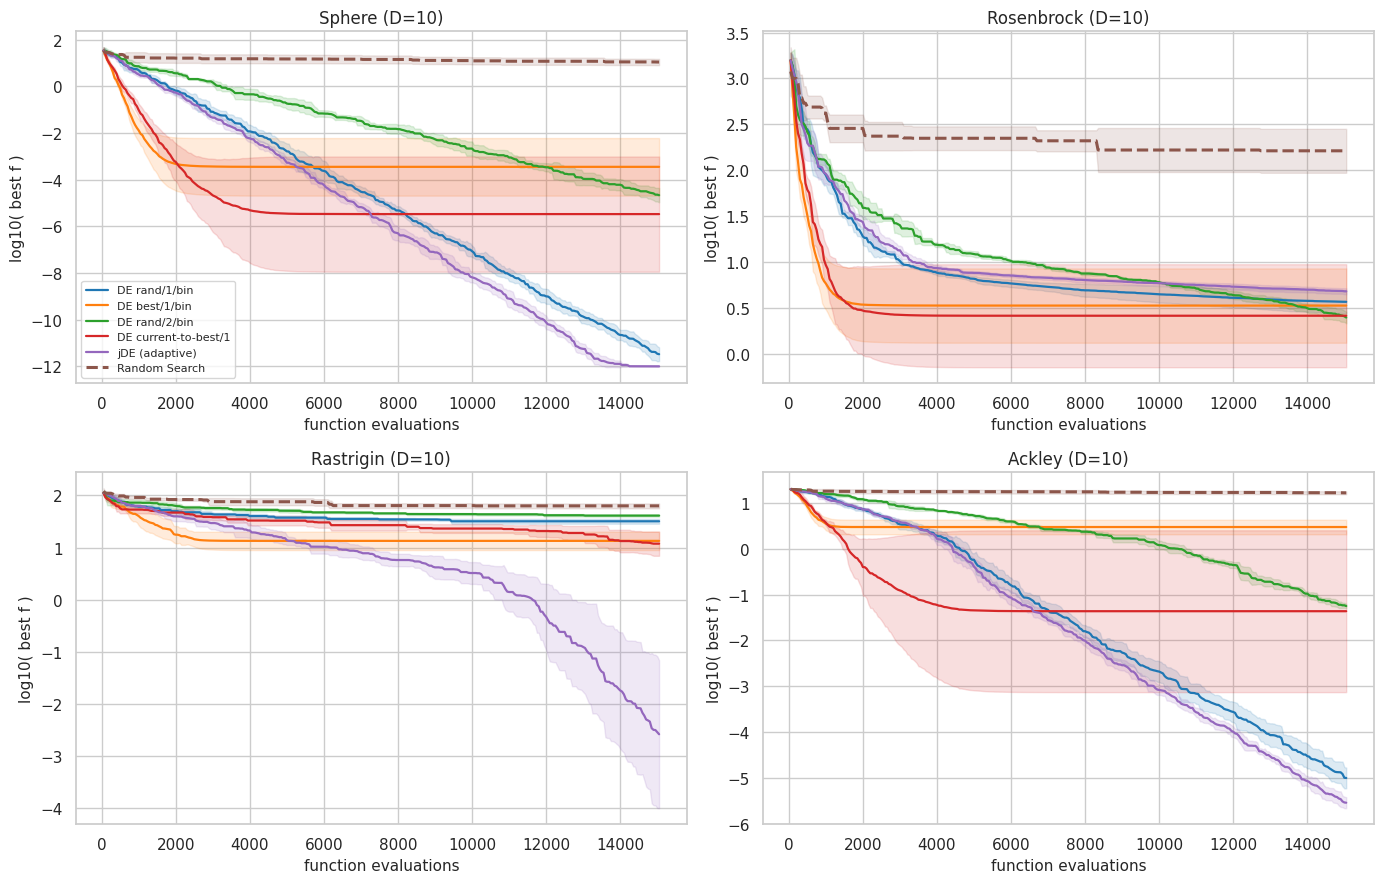

In [15]:
# ---- Figure 5 : courbes de convergence (moyenne log10 ± écart-type) pour chaque fonction ----
colors = dict(zip(list(BENCH_METHODS) + ["Random Search"], sns.color_palette("tab10", 6)))
x_ev = (np.arange(G_B + 1) + 1) * NP_B
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for a, fn in zip(axes.ravel(), BENCH_FUNCS):
    for m, A in curves[fn].items():
        L = np.log10(np.maximum(A, 1e-12)); mu_, sd_ = L.mean(0), L.std(0)
        a.plot(x_ev, mu_, color=colors[m], label=m, lw=2.2 if m == "Random Search" else 1.6, ls="--" if m == "Random Search" else "-")
        a.fill_between(x_ev, mu_ - sd_, mu_ + sd_, color=colors[m], alpha=.15)
    a.set_title(f"{fn} (D=10)"); a.set_xlabel("function evaluations"); a.set_ylabel("log10( best f )")
axes[0, 0].legend(fontsize=8)
save_fig("F5_benchmark_convergence")

In [16]:
# ---- Tableau 5 : résultats finaux sur les fonctions de référence ----
fin = pd.DataFrame(finals)
agg = fin.groupby(["Function", "Method"])["final_f"].agg(mean="mean", std="std", median="median", best="min",
                                                         success_rate=lambda s: (s < 1e-6).mean()).reset_index()
agg["Function"] = pd.Categorical(agg["Function"], BENCH_FUNCS, ordered=True)
agg = agg.sort_values(["Function", "mean"]).set_index(["Function", "Method"])
agg.to_csv(TAB_DIR / "T5_benchmark_results.csv")
with pd.option_context("display.float_format", "{:.3e}".format):
    display(agg)

# rang moyen sur l'ensemble des fonctions + test statistique (meilleur DE contre RS)
rk = fin.groupby(["Function", "Method"])["final_f"].mean().unstack(0).rank(axis=0)
rk["Mean rank"] = rk.mean(axis=1)
save_table(rk.sort_values("Mean rank"), "T6_benchmark_mean_rank", 2)
tests = []
for fn in BENCH_FUNCS:
    sub = fin[fin.Function == fn]
    best_de = sub[sub.Method != "Random Search"].groupby("Method")["final_f"].mean().idxmin()
    a = sub[sub.Method == best_de].final_f.values; b = sub[sub.Method == "Random Search"].final_f.values
    p = stats.mannwhitneyu(a, b, alternative="less").pvalue
    tests.append(dict(Function=fn, best_DE=best_de, DE_mean=a.mean(), RS_mean=b.mean(), ratio_RS_over_DE=b.mean() / max(a.mean(), 1e-12), p_value=p))
with pd.option_context("display.float_format", "{:.3e}".format):
    display(pd.DataFrame(tests).set_index("Function"))

mean       std    median      best  \
Function   Method                                                         
Sphere     jDE (adaptive)       7.428e-14 6.363e-14 3.132e-14 2.248e-14   
           DE rand/1/bin        3.942e-12 2.650e-12 3.663e-12 5.958e-13   
           DE rand/2/bin        2.892e-05 2.685e-05 1.744e-05 1.115e-05   
           DE current-to-best/1 2.422e-04 3.230e-04 6.070e-05 3.059e-10   
           DE best/1/bin        4.957e-03 8.925e-03 1.977e-04 1.021e-05   
           Random Search        1.167e+01 3.768e+00 1.181e+01 6.544e+00   
Rosenbrock DE rand/2/bin        2.510e+00 4.107e-01 2.470e+00 2.090e+00   
           DE rand/1/bin        3.842e+00 1.282e+00 2.938e+00 2.903e+00   
           DE current-to-best/1 4.177e+00 2.888e+00 4.283e+00 2.105e-01   
           jDE (adaptive)       4.804e+00 3.994e-01 4.748e+00 4.209e+00   
           DE best/1/bin        5.096e+00 4.773e+00 1.944e+00 1.187e+00   
           Random Search        1.867e+02 1.016e+02 1.595e+02 6.293e+01   
Rastrigin  jDE (adaptive)       4.908e-02 7.184e-02 1.331e-03 5.264e-05   
           DE current-to-best/1 1.373e+01 8.494e+00 1.211e+01 6.616e+00   
           DE best/1/bin        1.441e+01 5.256e+00 1.393e+01 6.259e+00   
           DE rand/1/bin        3.203e+01 3.626e+00 3.298e+01 2.596e+01   
           DE rand/2/bin        4.098e+01 2.045e+00 4.079e+01 3.823e+01   
           Random Search        6.324e+01 7.569e+00 6.069e+01 5.558e+01   
Ackley     jDE (adaptive)       3.037e-06 8.969e-07 2.965e-06 1.873e-06   
           DE rand/1/bin        1.152e-05 6.150e-06 1.116e-05 5.362e-06   
           DE rand/2/bin        5.640e-02 7.158e-03 5.453e-02 4.725e-02   
           DE current-to-best/1 6.937e-01 6.328e-01 1.155e+00 1.363e-04   
           DE best/1/bin        3.174e+00 1.500e+00 2.580e+00 2.015e+00   
           Random Search        1.642e+01 1.286e+00 1.676e+01 1.440e+01   

                                 success_rate  
Function   Method                              
Sphere     jDE (adaptive)           1.000e+00  
           DE rand/1/bin            1.000e+00  
           DE rand/2/bin            0.000e+00  
           DE current-to-best/1     4.000e-01  
           DE best/1/bin            0.000e+00  
           Random Search            0.000e+00  
Rosenbrock DE rand/2/bin            0.000e+00  
           DE rand/1/bin            0.000e+00  
           DE current-to-best/1     0.000e+00  
           jDE (adaptive)           0.000e+00  
           DE best/1/bin            0.000e+00  
           Random Search            0.000e+00  
Rastrigin  jDE (adaptive)           0.000e+00  
           DE current-to-best/1     0.000e+00  
           DE best/1/bin            0.000e+00  
           DE rand/1/bin            0.000e+00  
           DE rand/2/bin            0.000e+00  
           Random Search            0.000e+00  
Ackley     jDE (adaptive)           0.000e+00  
           DE rand/1/bin            0.000e+00  
           DE rand/2/bin            0.000e+00  
           DE current-to-best/1     0.000e+00  
           DE best/1/bin            0.000e+00  
           Random Search            0.000e+00

Function,Ackley,Rastrigin,Rosenbrock,Sphere,Mean rank
Method,,,,,
jDE (adaptive),1.0,1.0,4.0,1.0,1.75
DE rand/1/bin,2.0,4.0,2.0,2.0,2.50
DE rand/2/bin,3.0,5.0,1.0,3.0,3.00
DE current-to-best/1,4.0,2.0,3.0,4.0,3.25
DE best/1/bin,5.0,3.0,5.0,5.0,4.50
Random Search,6.0,6.0,6.0,6.0,6.00


,best_DE,DE_mean,RS_mean,ratio_RS_over_DE,p_value
Function,,,,,
Sphere,jDE (adaptive),7.428e-14,1.167e+01,1.167e+13,3.968e-03
Rosenbrock,DE rand/2/bin,2.510e+00,1.867e+02,7.437e+01,3.968e-03
Rastrigin,jDE (adaptive),4.908e-02,6.324e+01,1.288e+03,3.968e-03
Ackley,jDE (adaptive),3.037e-06,1.642e+01,5.407e+06,3.968e-03


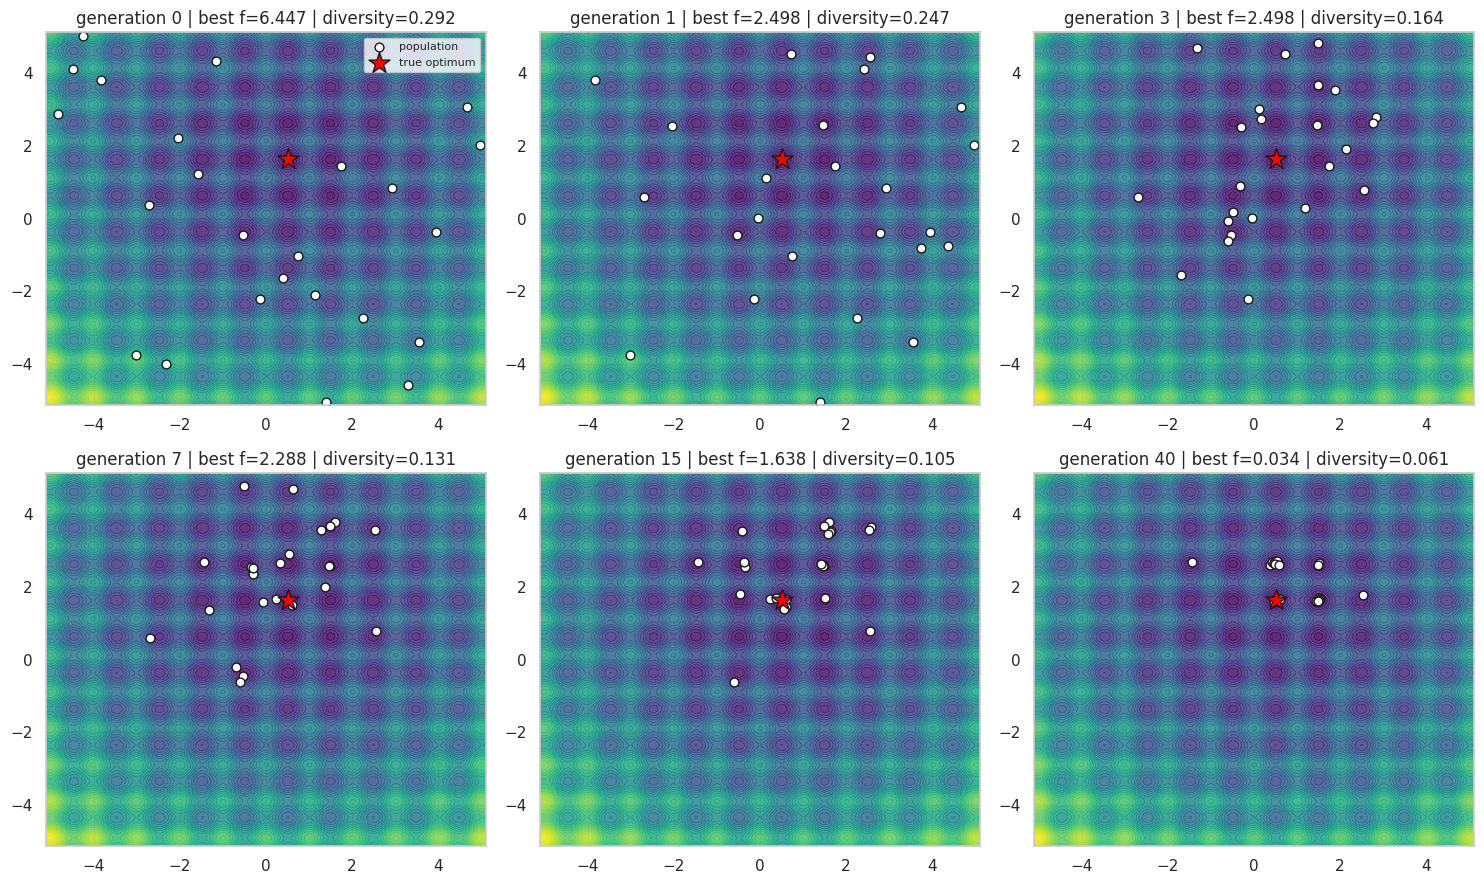

In [17]:
# ---- Figure 6 : visualisation 2D de l'évolution de la population sur Rastrigin (montre l'exploration puis l'exploitation) ----
f2, bnd2, sh2 = make_bench("Rastrigin", D=2, seed=7)
de2 = DifferentialEvolution(f2, bnd2, pop_size=24, F=0.5, CR=0.9, max_gen=40, vectorized=True, seed=3).run()
gx = np.linspace(bnd2[0][0], bnd2[0][1], 300); GX, GY = np.meshgrid(gx, gx)
GZ = f2(np.c_[GX.ravel(), GY.ravel()]).reshape(GX.shape)
snaps = [0, 1, 3, 7, 15, 40]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for a, g in zip(axes.ravel(), snaps):
    a.contourf(GX, GY, GZ, levels=30, cmap="viridis", alpha=.85)
    P = de2.pop_hist[g]; a.scatter(P[:, 0], P[:, 1], c="white", edgecolor="k", s=40, label="population")
    a.scatter(*sh2, marker="*", s=250, c="red", edgecolor="k", label="true optimum")
    a.set_title(f"generation {g} | best f={de2.history[g]['best_f']:.3f} | diversity={de2.history[g]['diversity']:.3f}")
axes[0, 0].legend(loc="upper right", fontsize=8)
save_fig("F6_DE_population_2D")

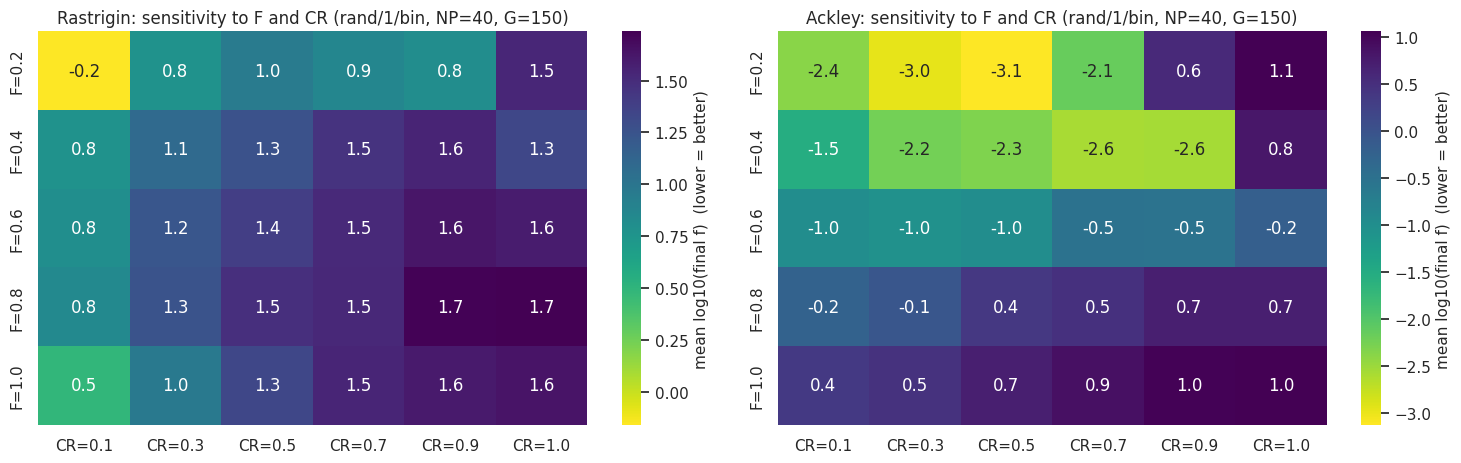

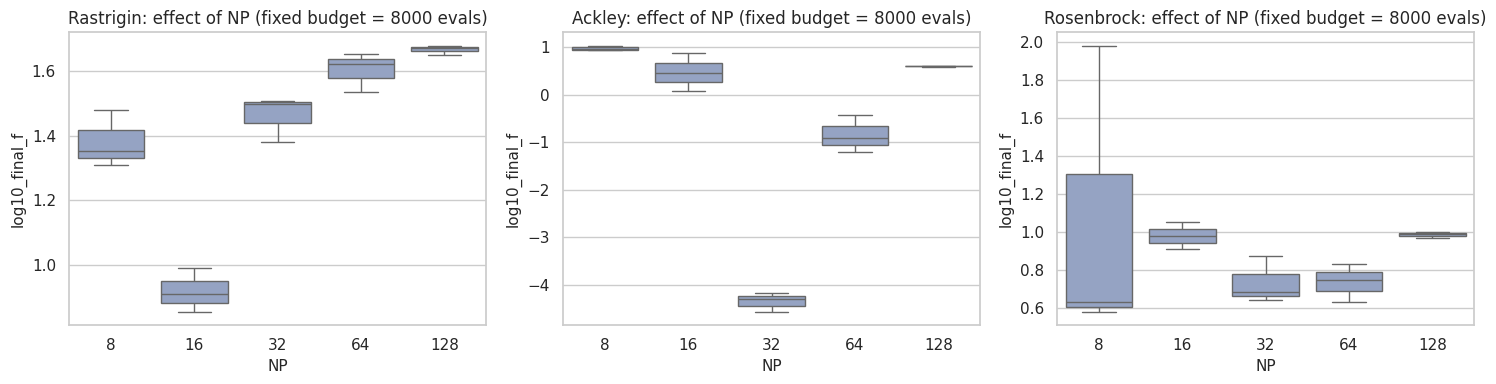

mean    std
Function   NP               
Ackley     8    0.974  0.052
           16   0.470  0.405
           32  -4.357  0.201
           64  -0.843  0.396
           128  0.599  0.008
Rastrigin  8    1.380  0.089
           16   0.918  0.068
           32   1.462  0.071
           64   1.602  0.061
           128  1.666  0.015
Rosenbrock 8    1.063  0.795
           16   0.979  0.070
           32   0.734  0.124
           64   0.735  0.100
           128  0.985  0.016

In [18]:
# ---- Figure 7 : sensibilité de DE à F et CR (heatmap) et à NP pour un budget fixe ----
Fs, CRs = [0.2, 0.4, 0.6, 0.8, 1.0], [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sens_rows = []
for a, fn in zip(axes, ["Rastrigin", "Ackley"]):
    f, bnd, _ = make_bench(fn)
    Z = np.zeros((len(Fs), len(CRs)))
    for i, Fv_ in enumerate(Fs):
        for j, CRv_ in enumerate(CRs):
            vals = [DifferentialEvolution(f, bnd, pop_size=40, F=Fv_, CR=CRv_, strategy="rand1bin", max_gen=150,
                                          vectorized=True, seed=50 + r).run().best_f for r in range(max(3, RUNS_B // 2))]
            Z[i, j] = np.mean(np.log10(np.maximum(vals, 1e-12))); sens_rows.append(dict(Function=fn, F=Fv_, CR=CRv_, mean_log10_f=Z[i, j]))
    sns.heatmap(pd.DataFrame(Z, index=[f"F={v}" for v in Fs], columns=[f"CR={v}" for v in CRs]), annot=True, fmt=".1f",
                cmap="viridis_r", ax=a, cbar_kws={"label": "mean log10(final f)  (lower = better)"})
    a.set_title(f"{fn}: sensitivity to F and CR (rand/1/bin, NP=40, G=150)")
save_fig("F7a_sensitivity_F_CR")
pd.DataFrame(sens_rows).to_csv(TAB_DIR / "T7_sensitivity_F_CR.csv", index=False)

BUDGET = 8000; NPs = [8, 16, 32, 64, 128]
rows = []
for fn in ["Rastrigin", "Ackley", "Rosenbrock"]:
    f, bnd, _ = make_bench(fn)
    for NP_ in NPs:
        for r in range(max(3, RUNS_B // 2)):
            b = DifferentialEvolution(f, bnd, pop_size=NP_, F=0.5, CR=0.9, max_gen=BUDGET // NP_ - 1, vectorized=True, seed=70 + r).run().best_f
            rows.append(dict(Function=fn, NP=NP_, log10_final_f=np.log10(max(b, 1e-12))))
dfNP = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for a, fn in zip(axes, ["Rastrigin", "Ackley", "Rosenbrock"]):
    sns.boxplot(data=dfNP[dfNP.Function == fn], x="NP", y="log10_final_f", ax=a, color="#8da0cb")
    a.set_title(f"{fn}: effect of NP (fixed budget = {BUDGET} evals)")
save_fig("F7b_sensitivity_NP")
save_table(dfNP.groupby(["Function", "NP"])["log10_final_f"].agg(["mean", "std"]), "T8_sensitivity_NP", 3)

## 7) Application de DE au LSTM — recherche des meilleurs hyperparamètres

**Cadre équitable pour la comparaison :**
- Même **fonction objectif** $f(x)=1-\text{AUPRC}_{val}$, mêmes **seeds d'entraînement** (`SEEDS_OBJ`) pour toutes les évaluations ⇒ « nombres aléatoires communs » (Common Random Numbers). L'objectif est la **moyenne de l'AUPRC sur plusieurs seeds** (`obj_seeds`), ce qui réduit fortement le bruit de sélection (effet « winner's curse »).
- Même **budget** : $N_{eval}=NP\,(G+1)$ entraînements pour DE comme pour Random Search.
- **Test n'est jamais utilisé** dans la recherche ; la sélection se fait sur Validation uniquement.
- La fonction objectif entraîne chaque modèle seulement `epochs_search` epochs (approximation bon marché de la qualité du modèle), puis nous ré-entraînons le meilleur complètement dans la section finale.

**Pourquoi l'AUPRC et non l'Accuracy ?** L'ensemble est déséquilibré (~2% de positifs) ; un modèle qui prédit toujours « pas de sepsis » obtient ~98% d'Accuracy. L'AUPRC (aire sous la courbe Precision–Recall), elle, mesure la qualité du classement pour les cas rares, et sa référence aléatoire = la prévalence et non 0.5.

In [19]:
HP_NAMES  = ["hidden", "layers", "dropout", "log10_lr", "log10_wd", "window"]
HP_BOUNDS = [(16, 129), (1, 4), (0.2, 0.6), (-5.0, -2.5), (-6.0, -2.0), (6, WMAX + 1)]
SEED_FIT  = 7
SEEDS_OBJ = [SEED_FIT + k for k in range(CFG["obj_seeds"])]     # seeds utilisées pour estimer l'objectif (moyenne ⇒ moins de bruit)

def decode_hp(x):
    """vecteur réel de DE → paramètres du LSTM (entiers par floor, et lr/wd par 10^x)"""
    return dict(hidden=int(np.clip(np.floor(x[0]), 16, 128)), layers=int(np.clip(np.floor(x[1]), 1, 3)),
                dropout=float(x[2]), lr=float(10 ** x[3]), wd=float(10 ** x[4]),
                window=int(np.clip(np.floor(x[5]), 6, WMAX)))

DEFAULT_HP = dict(hidden=64, layers=1, dropout=0.2, lr=1e-3, wd=1e-5, window=12)

def make_objective(log):
    cache = {}
    def obj(x):
        hp = decode_hp(x)
        key = (hp["hidden"], hp["layers"], round(hp["dropout"], 3), round(float(np.log10(hp["lr"])), 3),
               round(float(np.log10(hp["wd"])), 3), hp["window"])
        cached = key in cache
        if not cached:
            runs = []
            for sd in SEEDS_OBJ:                                  # moyenne sur plusieurs seeds
                try:
                    runs.append(train_model(hp, CFG["epochs_search"], sd, CFG["neg_ratio"]))
                except RuntimeError as e:                         # par ex. mémoire GPU insuffisante pour une grosse combinaison
                    print("Erreur pendant l'entraînement :", str(e)[:80]); torch.cuda.empty_cache()
            if runs:
                r = dict(best_ap=float(np.mean([q["best_ap"] for q in runs])),
                         auc=float(np.mean([q["history"]["val_auroc"].iloc[max(q["best_epoch"] - 1, 0)] for q in runs])),
                         best_epoch=int(np.median([q["best_epoch"] for q in runs])),
                         time_s=float(sum(q["time_s"] for q in runs)), n_params=runs[0]["n_params"])
            else:
                r = dict(best_ap=0.0, auc=0.5, best_epoch=0, time_s=0.0, n_params=0)
            cache[key] = r
        r = cache[key]
        log.append(dict(eval=len(log) + 1, **hp, val_auprc=r["best_ap"], val_auroc=r["auc"], f=1 - r["best_ap"],
                        time_s=0.0 if cached else r["time_s"], best_epoch=r["best_epoch"], n_params=r["n_params"], cached=cached))
        return 1.0 - r["best_ap"]
    return obj

NP_, G_ = CFG["de_pop"], CFG["de_gen"]
N_BUDGET = NP_ * (G_ + 1)
print(f"Budget de recherche : NP={NP_} × (G+1={G_+1}) = {N_BUDGET} configurations évaluées pour DE comme pour RS "
      f"(chacune sur {len(SEEDS_OBJ)} seed(s))")

# ---- Configuration manuelle (Default) avec exactement le même protocole de recherche (mêmes seeds) ----
t0_ = time.time()
runs_def = [train_model(DEFAULT_HP, CFG["epochs_search"], sd, CFG["neg_ratio"]) for sd in SEEDS_OBJ]
r_def = runs_def[0]
DEFAULT_SEARCH_AP = float(np.mean([q["best_ap"] for q in runs_def]))
print(f"Default (protocole de recherche) : val AUPRC = {DEFAULT_SEARCH_AP:.4f}  [{time.time()-t0_:.0f}s]")

Budget de recherche : NP=20 × (G+1=11) = 220 configurations évaluées pour DE comme pour RS (chacune sur 2 seed(s))
Default (protocole de recherche) : val AUPRC = 0.0905  [8s]


In [20]:
# ---- Exécution de DE ----
de_log = []
t0_ = time.time()
de = DifferentialEvolution(make_objective(de_log), HP_BOUNDS, pop_size=NP_, F=DE_F, CR=DE_CR, strategy=DE_STRATEGY,
                           max_gen=G_, init="lhs", bound_handling="reflect", seed=SEED, verbose=True).run()
T_DE = time.time() - t0_
de_df = pd.DataFrame(de_log)
de_df["gen"] = np.r_[np.zeros(NP_, int), np.repeat(np.arange(1, G_ + 1), NP_)][:len(de_df)]
de_df.to_csv(TAB_DIR / "T9_DE_search_log.csv", index=False)
print(f"\nDE terminée en {T_DE/60:.1f} minutes | meilleure val AUPRC = {de_df.val_auprc.max():.4f}")

gen   0 | evals    20 | best 0.91172 | mean 0.92151 | div 0.289 | SR nan
gen   1 | evals    40 | best 0.9114 | mean 0.91577 | div 0.253 | SR 0.65
gen   2 | evals    60 | best 0.90554 | mean 0.91308 | div 0.251 | SR 0.50
gen   3 | evals    80 | best 0.90554 | mean 0.912 | div 0.222 | SR 0.40
gen   4 | evals   100 | best 0.90554 | mean 0.91072 | div 0.187 | SR 0.35
gen   5 | evals   120 | best 0.90479 | mean 0.91028 | div 0.166 | SR 0.35
gen   6 | evals   140 | best 0.90479 | mean 0.90981 | div 0.137 | SR 0.45
gen   7 | evals   160 | best 0.90479 | mean 0.90929 | div 0.130 | SR 0.40
gen   8 | evals   180 | best 0.90479 | mean 0.90889 | div 0.129 | SR 0.25
gen   9 | evals   200 | best 0.90479 | mean 0.90869 | div 0.126 | SR 0.10
gen  10 | evals   220 | best 0.90479 | mean 0.9085 | div 0.117 | SR 0.20

DE terminée en 68.6 minutes | meilleure val AUPRC = 0.0952


In [21]:
# ---- Exécution de Random Search avec le même budget ----
rs_log = []
obj_rs = make_objective(rs_log)
rr = np.random.default_rng(SEED + 1)
lo_b, hi_b = np.array(HP_BOUNDS)[:, 0], np.array(HP_BOUNDS)[:, 1]
t0_ = time.time()
for k in tqdm(range(N_BUDGET)):
    obj_rs(lo_b + rr.random(len(HP_BOUNDS)) * (hi_b - lo_b))
T_RS = time.time() - t0_
rs_df = pd.DataFrame(rs_log)
rs_df.to_csv(TAB_DIR / "T10_RS_search_log.csv", index=False)
print(f"RS terminée en {T_RS/60:.1f} minutes | meilleure val AUPRC = {rs_df.val_auprc.max():.4f}")

  0%|          | 0/220 [00:00<?, ?it/s]

RS terminée en 49.4 minutes | meilleure val AUPRC = 0.0908


### 7.1 Résultats de la recherche : les tableaux

In [22]:
def best_row(d): return d.loc[d.val_auprc.idxmax()]
bde, brs = best_row(de_df), best_row(rs_df)
HP_COLS = ["hidden", "layers", "dropout", "lr", "wd", "window"]
BEST_HP = {"Default": DEFAULT_HP,
           "Random Search": {k: (int(brs[k]) if k in ("hidden", "layers", "window") else float(brs[k])) for k in HP_COLS},
           "DE": {k: (int(bde[k]) if k in ("hidden", "layers", "window") else float(bde[k])) for k in HP_COLS}}
tab_hp = pd.DataFrame(BEST_HP).T
tab_hp["val AUPRC (search protocol)"] = [DEFAULT_SEARCH_AP, brs.val_auprc, bde.val_auprc]
tab_hp["n_params"] = [r_def["n_params"], int(brs.n_params), int(bde.n_params)]
tab_hp["train time/eval (s)"] = [r_def["time_s"], brs.time_s, bde.time_s]
tab_hp["lr"] = tab_hp["lr"].map(lambda v: f"{v:.2e}"); tab_hp["wd"] = tab_hp["wd"].map(lambda v: f"{v:.2e}")
save_table(tab_hp, "T11_best_hyperparameters")
json.dump(BEST_HP, open("best_hyperparameters.json", "w"), indent=2)

# ---- Statistiques de qualité de tous les essais + efficacité ----
def best_so_far(d): return np.maximum.accumulate(d.val_auprc.values)
bsf_de, bsf_rs = best_so_far(de_df), best_so_far(rs_df)
top10_thr = np.quantile(np.r_[de_df.val_auprc, rs_df.val_auprc], 0.9)
def first_reach(bsf, thr):
    i = np.where(bsf >= thr)[0]; return int(i[0] + 1) if len(i) else np.nan
rows = []
for name, d, bsf in [("DE", de_df, bsf_de), ("Random Search", rs_df, bsf_rs)]:
    rows.append({"Method": name, "Evaluations": len(d), "Best AUPRC": d.val_auprc.max(), "Mean AUPRC": d.val_auprc.mean(),
                 "Median AUPRC": d.val_auprc.median(), "Std AUPRC": d.val_auprc.std(),
                 "% evals > Default": 100 * (d.val_auprc > DEFAULT_SEARCH_AP).mean(),
                 "% evals in pooled top-10%": 100 * (d.val_auprc >= top10_thr).mean(),
                 "Evals to beat Default": first_reach(bsf, DEFAULT_SEARCH_AP + 1e-9),
                 "Cache hits": int(d.cached.sum())})
tab_stats = pd.DataFrame(rows).set_index("Method")
save_table(tab_stats, "T12_search_statistics")

# Combien d'évaluations DE a-t-elle nécessité pour égaler le meilleur résultat final de RS ? (et inversement)
n_match = first_reach(bsf_de, bsf_rs[-1] - 1e-12)
n_match_rev = first_reach(bsf_rs, bsf_de[-1] - 1e-12)
checkpoints = [int(N_BUDGET * q) for q in (.25, .5, .75, 1.0)]
tab_eff = pd.DataFrame({"Budget used": checkpoints,
                        "DE best-so-far": [bsf_de[c - 1] for c in checkpoints],
                        "RS best-so-far": [bsf_rs[c - 1] for c in checkpoints]})
tab_eff["DE − RS"] = tab_eff["DE best-so-far"] - tab_eff["RS best-so-far"]
tab_eff = tab_eff.set_index("Budget used"); save_table(tab_eff, "T13_efficiency")
print(f"DE a nécessité {n_match} évaluations pour égaler le meilleur résultat final de RS ({N_BUDGET} évaluations)."
      if not np.isnan(n_match) else "DE n'a pas atteint le niveau final de RS dans le budget imparti.")
print(f"RS a nécessité {n_match_rev} évaluations pour égaler le meilleur résultat final de DE." if not np.isnan(n_match_rev) else "RS n'a jamais atteint le niveau final de DE avec le même budget.")

,hidden,layers,dropout,lr,wd,window,val AUPRC (search protocol),n_params,train time/eval (s)
Default,64.0,1.0,0.2000,1.00e-03,1.00e-05,12.0,0.0905,46657,4.2842
Random Search,63.0,2.0,0.4813,5.68e-04,1.75e-04,6.0,0.0908,77868,10.8204
DE,98.0,2.0,0.2548,2.95e-03,7.69e-06,29.0,0.0952,164053,23.8601


,Evaluations,Best AUPRC,Mean AUPRC,Median AUPRC,Std AUPRC,% evals > Default,% evals in pooled top-10%,Evals to beat Default,Cache hits
Method,,,,,,,,,
DE,220,0.0952,0.0865,0.0877,0.0054,15.9091,18.6364,49,0
Random Search,220,0.0908,0.0781,0.0806,0.0086,0.4545,1.3636,52,0


,DE best-so-far,RS best-so-far,DE − RS
Budget used,,,
55,0.0945,0.0908,0.0037
110,0.0952,0.0908,0.0044
165,0.0952,0.0908,0.0044
220,0.0952,0.0908,0.0044


DE a nécessité 49 évaluations pour égaler le meilleur résultat final de RS (220 évaluations).
RS n'a jamais atteint le niveau final de DE avec le même budget.


### 7.2 Résultats de la recherche : les courbes

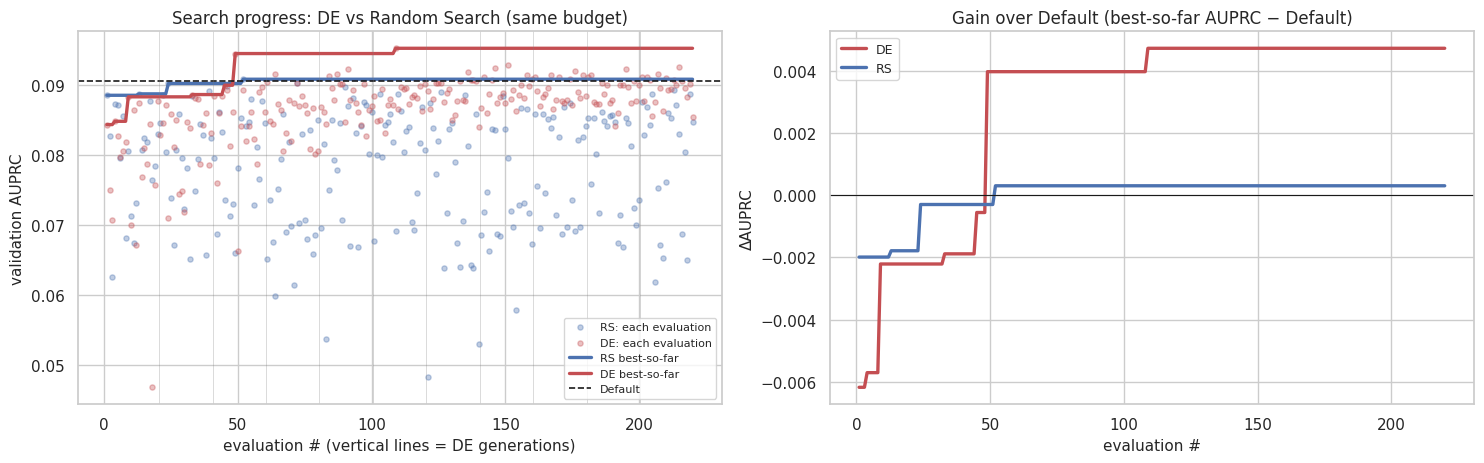

In [23]:
# ---- Figure 8 : best-so-far en fonction du nombre d'évaluations (DE vs RS vs Default) ----
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
xs = np.arange(1, N_BUDGET + 1)
ax[0].scatter(xs, rs_df.val_auprc, s=14, color="#4c72b0", alpha=.35, label="RS: each evaluation")
ax[0].scatter(xs, de_df.val_auprc, s=14, color="#c44e52", alpha=.35, label="DE: each evaluation")
ax[0].plot(xs, bsf_rs, color="#4c72b0", lw=2.4, label="RS best-so-far")
ax[0].plot(xs, bsf_de, color="#c44e52", lw=2.4, label="DE best-so-far")
ax[0].axhline(DEFAULT_SEARCH_AP, color="k", ls="--", lw=1.2, label="Default")
for g in range(1, G_ + 1): ax[0].axvline(g * NP_ + .5, color="gray", lw=.5, alpha=.4)
ax[0].set_xlabel("evaluation # (vertical lines = DE generations)"); ax[0].set_ylabel("validation AUPRC")
ax[0].set_title("Search progress: DE vs Random Search (same budget)"); ax[0].legend(fontsize=8)

gain = pd.DataFrame({"DE": bsf_de - DEFAULT_SEARCH_AP, "RS": bsf_rs - DEFAULT_SEARCH_AP}, index=xs)
gain.plot(ax=ax[1], color=["#c44e52", "#4c72b0"], lw=2.4); ax[1].axhline(0, color="k", lw=.8)
ax[1].set_title("Gain over Default (best-so-far AUPRC − Default)"); ax[1].set_xlabel("evaluation #"); ax[1].set_ylabel("ΔAUPRC")
save_fig("F8_search_progress_DE_vs_RS")

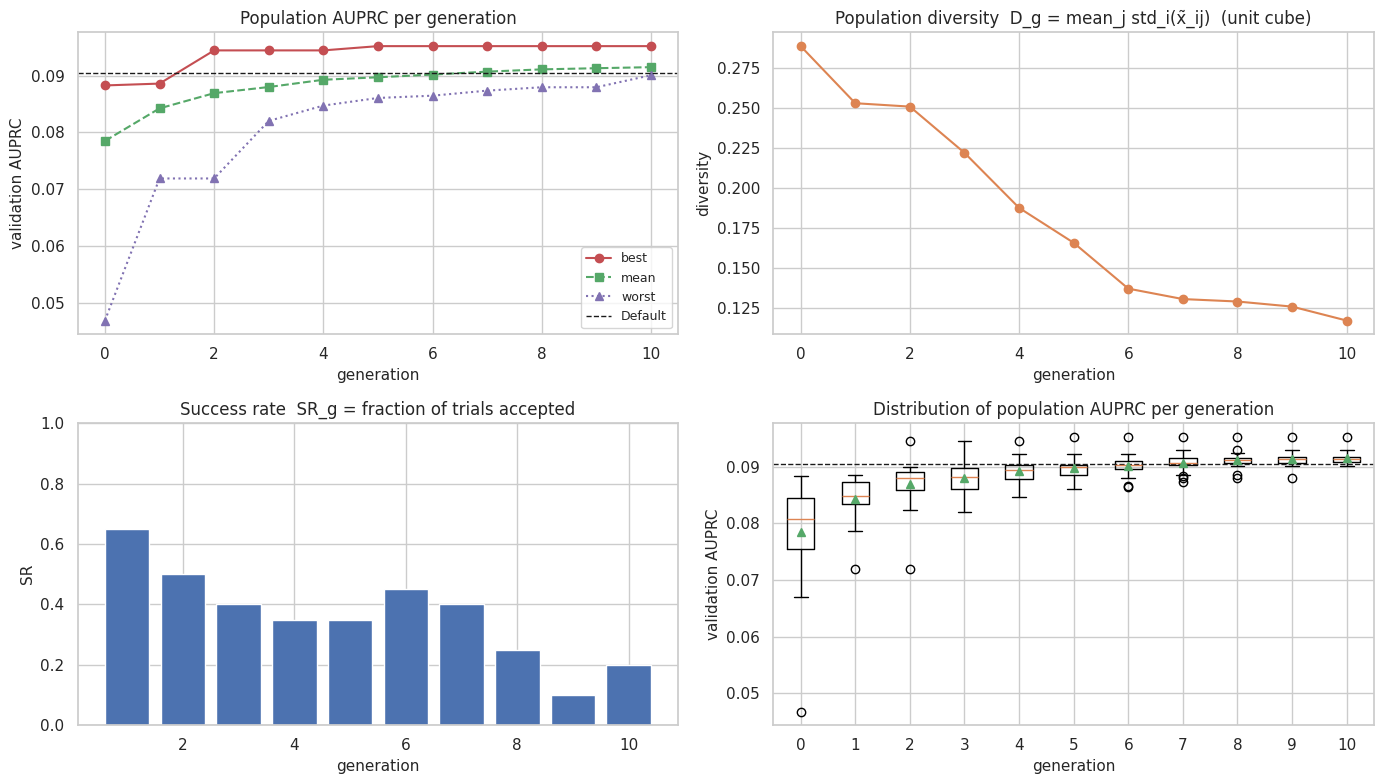

,n_evals,best_f,mean_f,median_f,worst_f,std_f,diversity,success_rate,mean_F,mean_CR
gen,,,,,,,,,,
0,20,0.9117,0.9215,0.9192,0.9532,0.0094,0.2887,NaN,0.6,0.9
1,40,0.9114,0.9158,0.9151,0.9281,0.0040,0.2530,0.65,0.6,0.9
2,60,0.9055,0.9131,0.9120,0.9281,0.0043,0.2508,0.50,0.6,0.9
3,80,0.9055,0.9120,0.9118,0.9180,0.0027,0.2219,0.40,0.6,0.9
4,100,0.9055,0.9107,0.9106,0.9153,0.0022,0.1874,0.35,0.6,0.9
5,120,0.9048,0.9103,0.9102,0.9139,0.0020,0.1655,0.35,0.6,0.9
6,140,0.9048,0.9098,0.9097,0.9135,0.0019,0.1369,0.45,0.6,0.9
7,160,0.9048,0.9093,0.9093,0.9126,0.0017,0.1303,0.40,0.6,0.9
8,180,0.9048,0.9089,0.9089,0.9120,0.0014,0.1288,0.25,0.6,0.9


In [24]:
# ---- Figure 9 : diagnostic de DE (convergence, diversité, taux de succès, distribution de la population) ----
H = de.history_df.copy()
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax[0, 0].plot(H.gen, 1 - H.best_f, "o-", color="#c44e52", label="best"); ax[0, 0].plot(H.gen, 1 - H.mean_f, "s--", color="#55a868", label="mean")
ax[0, 0].plot(H.gen, 1 - H.worst_f, "^:", color="#8172b2", label="worst"); ax[0, 0].axhline(DEFAULT_SEARCH_AP, color="k", ls="--", lw=1, label="Default")
ax[0, 0].set_title("Population AUPRC per generation"); ax[0, 0].set_xlabel("generation"); ax[0, 0].set_ylabel("validation AUPRC"); ax[0, 0].legend()
ax[0, 1].plot(H.gen, H.diversity, "o-", color="#dd8452"); ax[0, 1].set_title("Population diversity  D_g = mean_j std_i(x̃_ij)  (unit cube)")
ax[0, 1].set_xlabel("generation"); ax[0, 1].set_ylabel("diversity")
ax[1, 0].bar(H.gen[1:], H.success_rate[1:], color="#4c72b0"); ax[1, 0].set_ylim(0, 1)
ax[1, 0].set_title("Success rate  SR_g = fraction of trials accepted"); ax[1, 0].set_xlabel("generation"); ax[1, 0].set_ylabel("SR")
data_box = [1 - fh for fh in de.fit_hist]
ax[1, 1].boxplot(data_box, showmeans=True); ax[1, 1].set_xticklabels(list(range(len(data_box))))
ax[1, 1].axhline(DEFAULT_SEARCH_AP, color="k", ls="--", lw=1); ax[1, 1].set_title("Distribution of population AUPRC per generation")
ax[1, 1].set_xlabel("generation"); ax[1, 1].set_ylabel("validation AUPRC")
save_fig("F9_DE_diagnostics")
save_table(H.set_index("gen"), "T14_DE_generation_history")

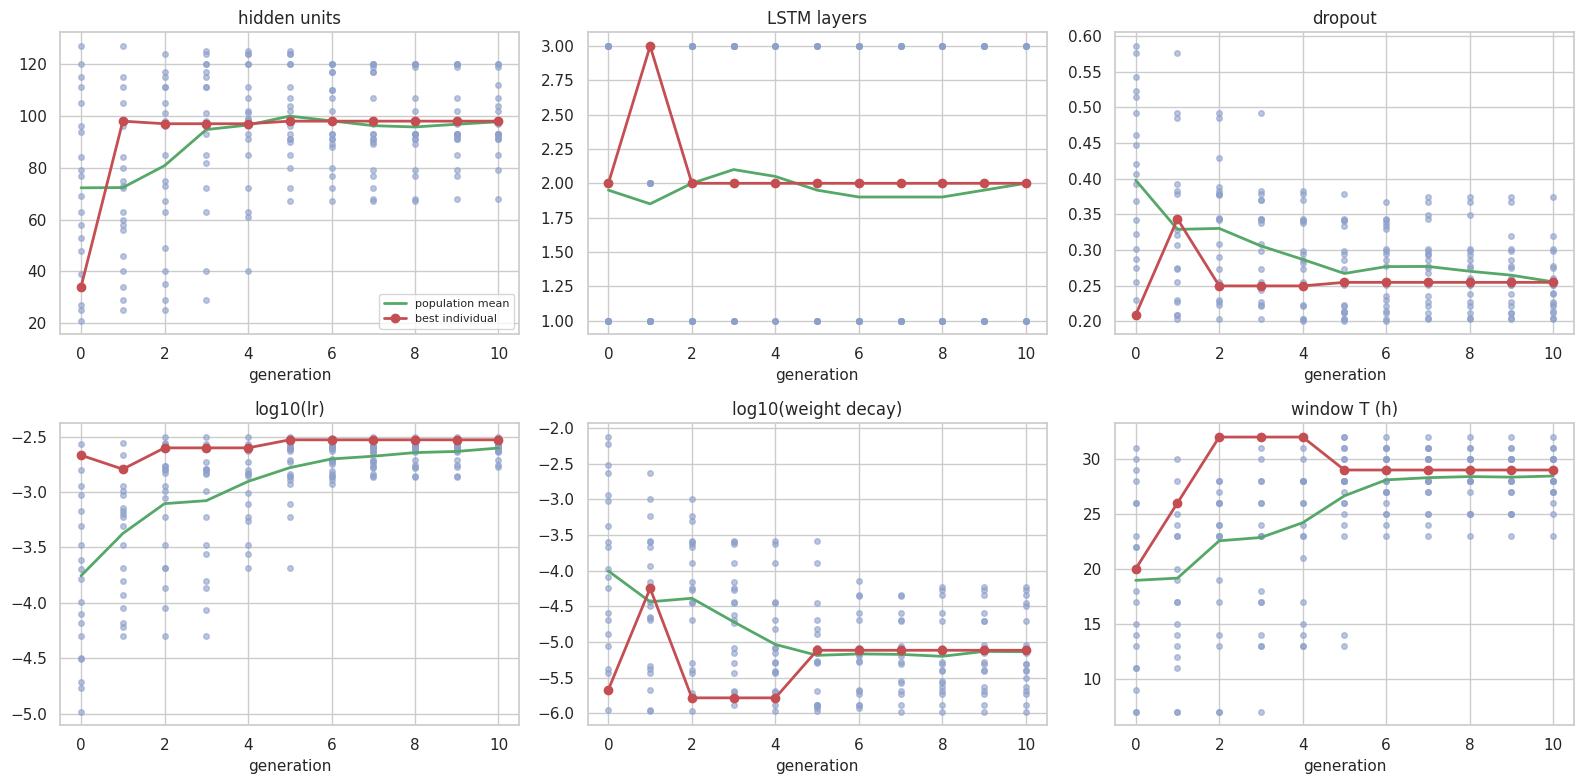

In [25]:
# ---- Figure 10 : trajectoires des hyperparamètres au fil des générations (comment DE « apprend » la bonne région) ----
labels = ["hidden units", "LSTM layers", "dropout", "log10(lr)", "log10(weight decay)", "window T (h)"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for k, a in enumerate(axes.ravel()):
    for g, P in enumerate(de.pop_hist):
        v = np.floor(P[:, k]) if k in (0, 1, 5) else P[:, k]
        a.scatter(np.full(len(v), g), v, s=16, color="#8da0cb", alpha=.6)
    mean_line = [(np.floor(P[:, k]) if k in (0, 1, 5) else P[:, k]).mean() for P in de.pop_hist]
    best_line = [(np.floor(b[k]) if k in (0, 1, 5) else b[k]) for b in de.best_x_hist]
    a.plot(mean_line, color="#55a868", lw=2, label="population mean"); a.plot(best_line, color="#c44e52", lw=2, marker="o", label="best individual")
    a.set_title(labels[k]); a.set_xlabel("generation")
axes[0, 0].legend(fontsize=8)
save_fig("F10_hyperparameter_trajectories")

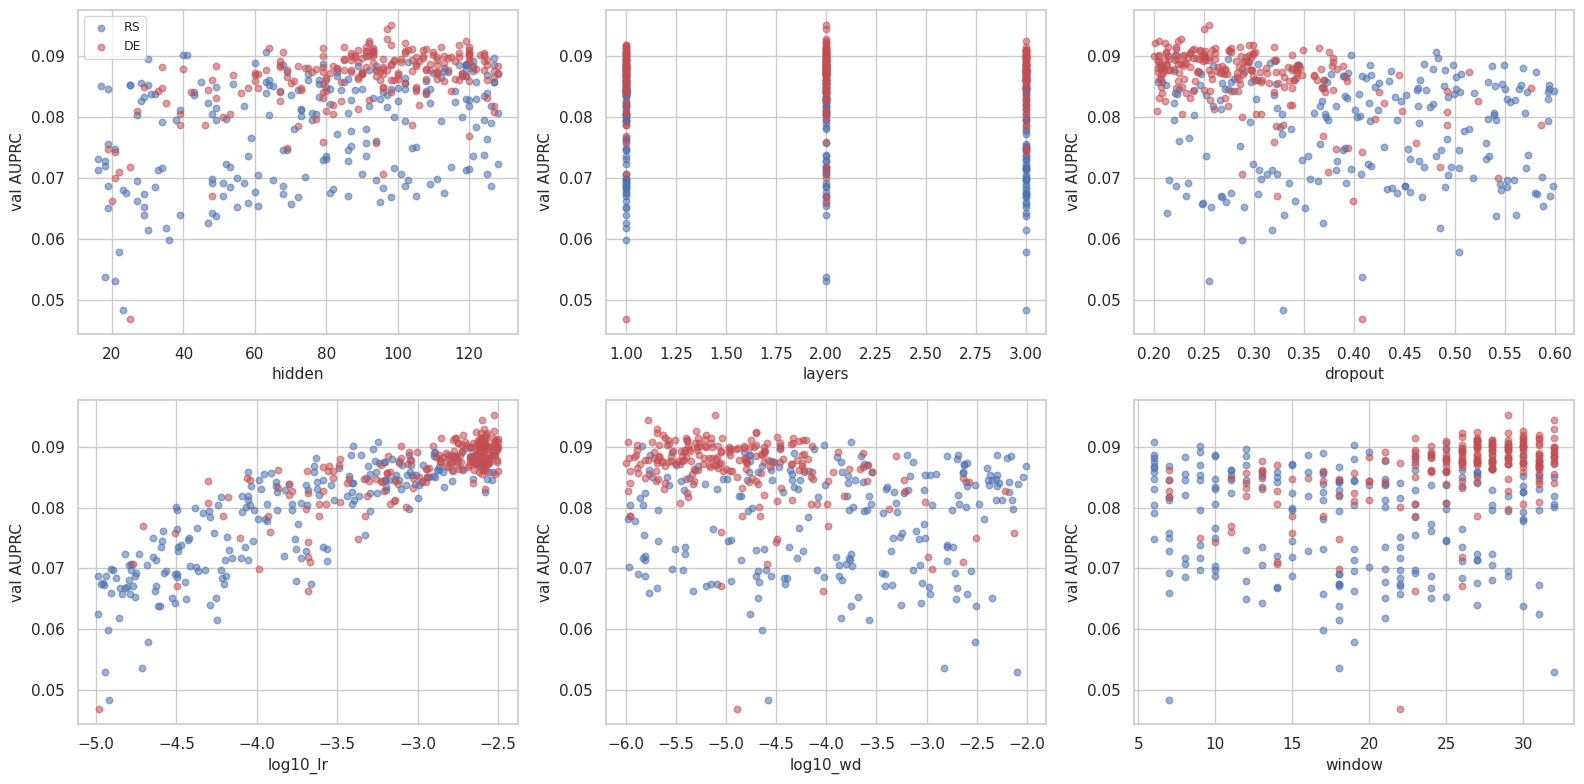

,Spearman ρ (pooled),p-value,ρ (DE only),ρ (RS only),|ρ| pooled
log10_lr,0.8523,0.0000,0.6840,0.8515,0.8523
dropout,-0.4444,0.0000,-0.4093,-0.0254,0.4444
window,0.4033,0.0000,0.4814,-0.1095,0.4033
hidden,0.3991,0.0000,0.3864,0.3318,0.3991
log10_wd,-0.3246,0.0000,-0.2508,0.0660,0.3246
layers,-0.0000,0.9997,0.0241,-0.1310,0.0000


In [26]:
# ---- Figure 11 : tous les essais : paramètre en fonction de l'AUPRC (DE et RS) ----
def hp_view(d):
    v = d.copy(); v["log10_lr"] = np.log10(v.lr); v["log10_wd"] = np.log10(v.wd); return v
dv, rv = hp_view(de_df), hp_view(rs_df)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for k, a in zip(HP_NAMES, axes.ravel()):
    a.scatter(rv[k], rv.val_auprc, s=22, color="#4c72b0", alpha=.55, label="RS")
    a.scatter(dv[k], dv.val_auprc, s=22, color="#c44e52", alpha=.55, label="DE")
    a.set_xlabel(k); a.set_ylabel("val AUPRC")
axes[0, 0].legend()
save_fig("F11_hyperparameter_vs_performance")

# ---- Tableau 15 : « importance » des paramètres (Spearman avec l'AUPRC sur tous les essais) ----
allv = pd.concat([dv.assign(method="DE"), rv.assign(method="RS")])
imp = pd.DataFrame({n: {"Spearman ρ (pooled)": stats.spearmanr(allv[n], allv.val_auprc)[0],
                        "p-value": stats.spearmanr(allv[n], allv.val_auprc)[1],
                        "ρ (DE only)": stats.spearmanr(dv[n], dv.val_auprc)[0],
                        "ρ (RS only)": stats.spearmanr(rv[n], rv.val_auprc)[0]} for n in HP_NAMES}).T
imp["|ρ| pooled"] = imp["Spearman ρ (pooled)"].abs(); imp = imp.sort_values("|ρ| pooled", ascending=False)
save_table(imp, "T15_hyperparameter_importance")

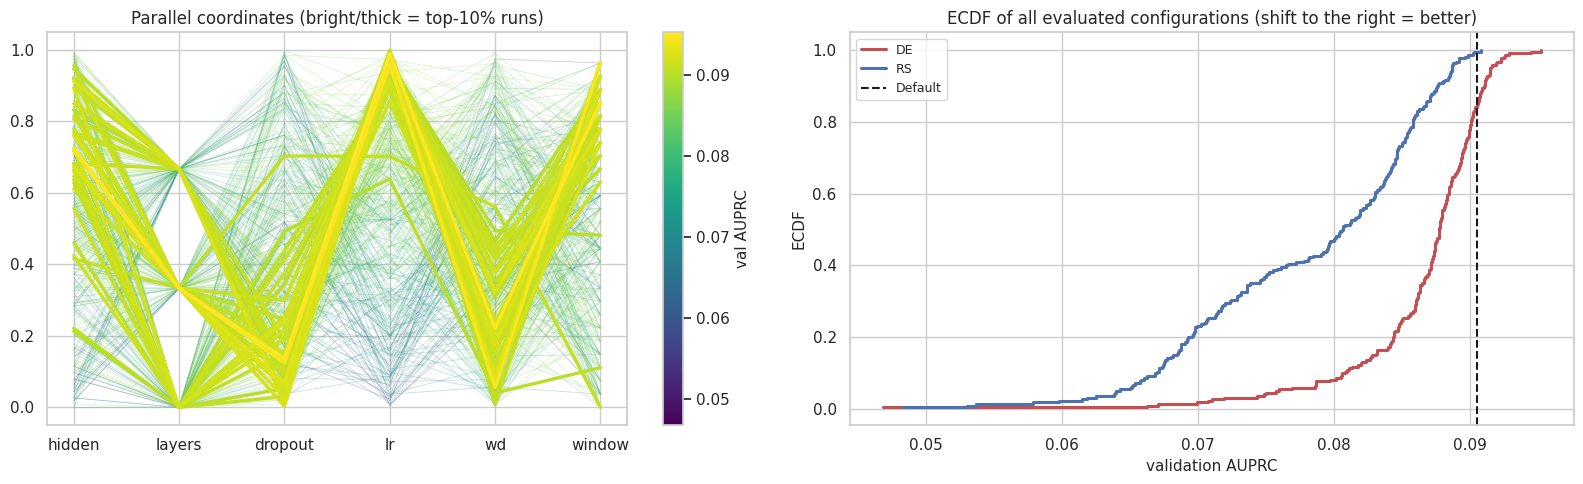

In [27]:
# ---- Figure 12 : Parallel coordinates des meilleurs essais + ECDF de la qualité des essais ----
def norm01(d):
    vals = {"hidden": d.hidden, "layers": d.layers, "dropout": d.dropout, "log10_lr": np.log10(d.lr),
            "log10_wd": np.log10(d.wd), "window": d.window}
    return pd.DataFrame({n: (vals[n] - lo) / (hi - lo) for n, (lo, hi) in zip(HP_NAMES, HP_BOUNDS)})
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
pool = pd.concat([de_df.assign(method="DE"), rs_df.assign(method="RS")]).reset_index(drop=True)
Nrm = norm01(pool); cmap = plt.cm.viridis; vmin, vmax = pool.val_auprc.min(), pool.val_auprc.max()
order = np.argsort(pool.val_auprc.values)
for i in order:
    c = cmap((pool.val_auprc[i] - vmin) / max(vmax - vmin, 1e-9))
    lw, al = (2.4, 1.0) if pool.val_auprc[i] >= top10_thr else (.6, .25)
    ax[0].plot(range(6), Nrm.iloc[i].values, color=c, lw=lw, alpha=al)
ax[0].set_xticks(range(6)); ax[0].set_xticklabels(["hidden", "layers", "dropout", "lr", "wd", "window"])
ax[0].set_title("Parallel coordinates (bright/thick = top-10% runs)")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin, vmax)); plt.colorbar(sm, ax=ax[0], label="val AUPRC")
for d, c, n in [(de_df, "#c44e52", "DE"), (rs_df, "#4c72b0", "RS")]:
    v = np.sort(d.val_auprc.values); ax[1].step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=c, lw=2.2, label=n)
ax[1].axvline(DEFAULT_SEARCH_AP, color="k", ls="--", label="Default")
ax[1].set_xlabel("validation AUPRC"); ax[1].set_ylabel("ECDF"); ax[1].set_title("ECDF of all evaluated configurations (shift to the right = better)"); ax[1].legend()
save_fig("F12_parallel_coordinates_and_ECDF")

## 8) Évaluation finale sur l'ensemble de test (Test)

Nous ré-entraînons la meilleure configuration de chaque méthode (Default / RS / DE) **complètement** (`final_epochs` avec early stopping) avec plusieurs **seeds**, nous choisissons le **seuil** sur Validation uniquement, puis nous évaluons sur Test qui n'a jamais été utilisé. Les probabilités sont **calibrées (Platt)** sur Validation, et le modèle final évalué est l'**ensemble** (moyenne) des seeds, ce qui réduit la variance.

**Les métriques (équations) :** avec $TP, FP, TN, FN$ pour un seuil $\tau$ :
$$
\text{Precision}=\tfrac{TP}{TP+FP},\quad
\text{Recall (Sensitivity)}=\tfrac{TP}{TP+FN},\quad
\text{Specificity}=\tfrac{TN}{TN+FP},\quad
F_1=\tfrac{2\,P\,R}{P+R}
$$
$$
\text{Balanced Acc}=\tfrac{\text{Recall}+\text{Specificity}}{2},\qquad
\text{MCC}=\frac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}
$$
- **AUROC** $=P(\hat p_{pos}>\hat p_{neg})$ aire sous la courbe ROC (TPR en fonction de FPR).
- **AUPRC / Average Precision** $=\sum_n (R_n-R_{n-1})\,P_n$ (sa référence aléatoire = la prévalence).
- **Brier score** $=\frac1N\sum(\hat p_n-y_n)^2$ mesure la **calibration** (plus petit = meilleur).
- **Seuil :** $\tau^\star=\arg\max_\tau F_1(\tau)$ sur Validation.

**Métriques au niveau patient (cliniquement plus importantes) :** pour chaque patient qui développe un sepsis, nous cherchons la **première alerte**. 
- *Patient sensitivity* = proportion de patients en sepsis pour lesquels au moins une alerte a été émise.
- *Lead time* $=t_{label}-t_{alarm}+6$ heures avant le début clinique du sepsis (car l'étiquette commence 6 heures avant). Négatif = alerte tardive.
- *False-alarm patient rate* = proportion de patients non atteints ayant déclenché une alerte.

**La différence entre les méthodes (Bootstrap apparié au niveau patient) :** nous ré-échantillonnons les patients $B$ fois avec remise et calculons $\Delta=\text{AUPRC}_{DE}-\text{AUPRC}_{autre}$ sur le même échantillon ; nous fournissons la moyenne, l'intervalle de confiance à 95% ($2.5\%$–$97.5\%$) et la probabilité $\hat P(\Delta\le 0)$.

In [28]:
def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.maximum(pr[:-1] + rc[:-1], 1e-12)
    return float(th[int(np.argmax(f1))])

from sklearn.linear_model import LogisticRegression

def fit_platt(p_val, y_val):
    """Calibration de Platt (monotone ⇒ ne change pas le classement, donc ni l'AUROC ni l'AUPRC) apprise sur Validation uniquement."""
    z = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))[:, None]
    lr_ = LogisticRegression(C=1e6, max_iter=1000).fit(z(p_val), y_val)
    return lambda p: lr_.predict_proba(z(p))[:, 1]

def compute_metrics(y, p, thr):
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1)
    return dict(AUROC=roc_auc_score(y, p), AUPRC=average_precision_score(y, p), Precision=prec, Recall=rec,
                Specificity=spec, F1=2 * prec * rec / max(prec + rec, 1e-12), Accuracy=(tp + tn) / len(y),
                BalancedAcc=(rec + spec) / 2, MCC=matthews_corrcoef(y, yh), Brier=brier_score_loss(y, p),
                Threshold=thr, TP=int(tp), FP=int(fp), TN=int(tn), FN=int(fn))

y_val_s, y_test = y_all[va_rows], y_all[te_rows]
pc_test, it_test = pcode[te_rows], it_all[te_rows]
FINAL = {m: [] for m in BEST_HP}
for m, hp in BEST_HP.items():
    for s in range(CFG["n_seeds"]):
        r = train_model(hp, CFG["final_epochs"], 1000 + s, CFG["final_neg_ratio"], patience=10, return_model=True)
        pv_raw = predict_proba(r["model"], VAL_ROWS_t, hp["window"]); pt_raw = predict_proba(r["model"], TEST_ROWS_t, hp["window"])
        cal = fit_platt(pv_raw, y_val_s)                       # calibration apprise sur Validation uniquement
        pv, pt = cal(pv_raw), cal(pt_raw)
        thr = best_f1_threshold(y_val_s, pv)
        FINAL[m].append(dict(seed=s, hp=hp, history=r["history"], val_ap=r["best_ap"], pv=pv, pt=pt, thr=thr,
                             metrics=compute_metrics(y_test, pt, thr), n_params=r["n_params"], time_s=r["time_s"]))
        print(f"{m:14s} seed {s}: val AUPRC={r['best_ap']:.4f} | test AUPRC={FINAL[m][-1]['metrics']['AUPRC']:.4f} | AUROC={FINAL[m][-1]['metrics']['AUROC']:.4f} | epochs={r['best_epoch']}")
        del r["model"]
        if DEVICE.type == "cuda": torch.cuda.empty_cache()

Default        seed 0: val AUPRC=0.0888 | test AUPRC=0.1288 | AUROC=0.8433 | epochs=2
Default        seed 1: val AUPRC=0.0886 | test AUPRC=0.1250 | AUROC=0.8435 | epochs=2
Default        seed 2: val AUPRC=0.0909 | test AUPRC=0.1206 | AUROC=0.8391 | epochs=1
Random Search  seed 0: val AUPRC=0.0857 | test AUPRC=0.1170 | AUROC=0.8280 | epochs=8
Random Search  seed 1: val AUPRC=0.0855 | test AUPRC=0.1190 | AUROC=0.8456 | epochs=4
Random Search  seed 2: val AUPRC=0.0853 | test AUPRC=0.1247 | AUROC=0.8444 | epochs=4
DE             seed 0: val AUPRC=0.0817 | test AUPRC=0.1178 | AUROC=0.8442 | epochs=1
DE             seed 1: val AUPRC=0.0883 | test AUPRC=0.1201 | AUROC=0.8383 | epochs=1
DE             seed 2: val AUPRC=0.0864 | test AUPRC=0.1287 | AUROC=0.8373 | epochs=2


In [29]:
# ---- Tableau 16 : résultats sur Test (moyenne ± écart-type sur les seeds) + Tableau 17 : chaque seed ----
metric_names = ["AUPRC", "AUROC", "F1", "Precision", "Recall", "Specificity", "BalancedAcc", "MCC", "Accuracy", "Brier"]
raw = pd.DataFrame([dict(Method=m, seed=r["seed"], **{k: r["metrics"][k] for k in metric_names + ["Threshold"]})
                    for m, L in FINAL.items() for r in L])
raw.to_csv(TAB_DIR / "T17_test_metrics_per_seed.csv", index=False)
summ = raw.groupby("Method")[metric_names].agg(["mean", "std"])
tab_test = pd.DataFrame({k: [f"{summ.loc[m, (k, 'mean')]:.4f} ± {summ.loc[m, (k, 'std')]:.4f}" for m in BEST_HP] for k in metric_names}, index=list(BEST_HP))
tab_test.to_csv(TAB_DIR / "T16_test_metrics_mean_std.csv"); display(tab_test)
print("\nDétails de chaque seed :"); display(raw.set_index(["Method", "seed"]).round(4))

prev = y_test.mean()
print(f"\nPrévalence sur Test = {prev:.4f}  ⇒ AUPRC d'un modèle aléatoire ≈ {prev:.4f}")

,AUPRC,AUROC,F1,Precision,Recall,Specificity,BalancedAcc,MCC,Accuracy,Brier
Default,0.1248 ± 0.0041,0.8420 ± 0.0025,0.2036 ± 0.0079,0.1537 ± 0.0118,0.3034 ± 0.0130,0.9693 ± 0.0040,0.6364 ± 0.0046,0.1957 ± 0.0058,0.9574 ± 0.0037,0.0166 ± 0.0000
Random Search,0.1203 ± 0.0040,0.8393 ± 0.0098,0.1861 ± 0.0098,0.1342 ± 0.0292,0.3438 ± 0.0976,0.9564 ± 0.0206,0.6501 ± 0.0385,0.1875 ± 0.0051,0.9454 ± 0.0185,0.0166 ± 0.0000
DE,0.1222 ± 0.0057,0.8399 ± 0.0038,0.1893 ± 0.0075,0.1344 ± 0.0131,0.3283 ± 0.0471,0.9608 ± 0.0104,0.6445 ± 0.0184,0.1869 ± 0.0052,0.9494 ± 0.0094,0.0166 ± 0.0000



Détails de chaque seed :


AUPRC   AUROC      F1  Precision  Recall  Specificity  \
Method        seed                                                           
Default       0     0.1288  0.8433  0.1972     0.1428  0.3183       0.9652   
              1     0.1250  0.8435  0.2125     0.1663  0.2942       0.9731   
              2     0.1206  0.8391  0.2012     0.1519  0.2978       0.9697   
Random Search 0     0.1170  0.8280  0.1846     0.1239  0.3619       0.9534   
              1     0.1190  0.8456  0.1966     0.1672  0.2384       0.9784   
              2     0.1247  0.8444  0.1772     0.1115  0.4311       0.9374   
DE            0     0.1178  0.8442  0.1891     0.1400  0.2911       0.9674   
              1     0.1201  0.8383  0.1970     0.1438  0.3126       0.9661   
              2     0.1287  0.8373  0.1819     0.1195  0.3813       0.9488   

                    BalancedAcc     MCC  Accuracy   Brier  Threshold  
Method        seed                                                    
Default       0          0.6417  0.1920    0.9536  0.0166     0.0872  
              1          0.6337  0.2024    0.9610  0.0166     0.0891  
              2          0.6338  0.1928    0.9577  0.0166     0.0985  
Random Search 0          0.6576  0.1878    0.9428  0.0167     0.0746  
              1          0.6084  0.1823    0.9651  0.0166     0.1038  
              2          0.6842  0.1925    0.9283  0.0166     0.0669  
DE            0          0.6293  0.1811    0.9553  0.0166     0.0806  
              1          0.6393  0.1911    0.9544  0.0167     0.0814  
              2          0.6650  0.1886    0.9386  0.0166     0.0697


Prévalence sur Test = 0.0179  ⇒ AUPRC d'un modèle aléatoire ≈ 0.0179


Résultats sur Test de l'ensemble des seeds (modèle évalué dans les figures et les tests suivants) :


,AUPRC,AUROC,F1,Precision,Recall,Specificity,BalancedAcc,MCC,Accuracy,Brier
Default,0.1343,0.8499,0.2017,0.1890,0.2163,0.9831,0.5997,0.1866,0.9694,0.0166
Random Search,0.1277,0.8485,0.2035,0.1785,0.2365,0.9802,0.6083,0.1888,0.9669,0.0166
DE,0.1341,0.8496,0.2056,0.1489,0.3319,0.9654,0.6487,0.2014,0.9541,0.0166


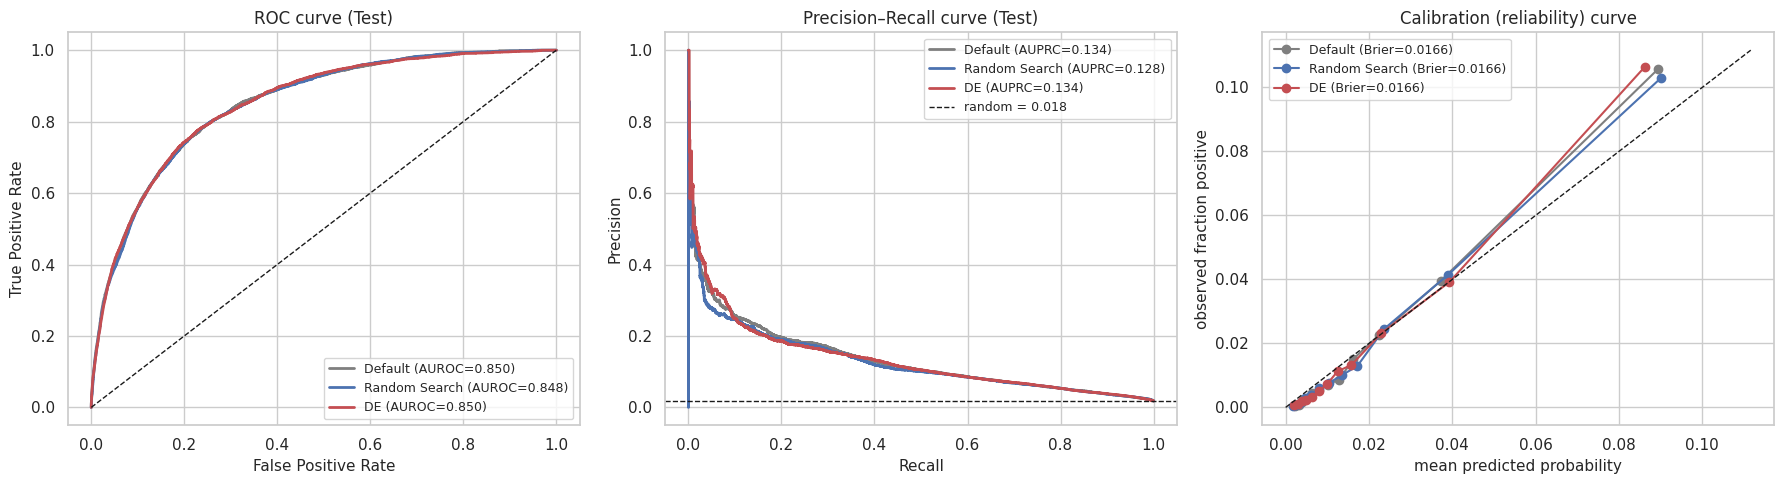

In [30]:
# ---- Modèle représentatif de chaque méthode = ENSEMBLE (moyenne des probabilités calibrées de tous les seeds) ----
def make_ensemble(L):
    pv = np.mean([r["pv"] for r in L], axis=0); pt = np.mean([r["pt"] for r in L], axis=0)
    thr = best_f1_threshold(y_val_s, pv)                                  # seuil choisi sur Validation uniquement
    best = max(L, key=lambda r: r["val_ap"])
    return dict(pv=pv, pt=pt, thr=thr, metrics=compute_metrics(y_test, pt, thr), history=best["history"],
                val_ap=average_precision_score(y_val_s, pv))
REP = {m: make_ensemble(L) for m, L in FINAL.items()}
tab_ens = pd.DataFrame({m: {k: REP[m]["metrics"][k] for k in metric_names} for m in REP}).T
print("Résultats sur Test de l'ensemble des seeds (modèle évalué dans les figures et les tests suivants) :")
save_table(tab_ens, "T16b_test_metrics_ensemble")
PAL = {"Default": "#7f7f7f", "Random Search": "#4c72b0", "DE": "#c44e52"}

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for m, r in REP.items():
    fpr, tpr, _ = roc_curve(y_test, r["pt"]); ax[0].plot(fpr, tpr, color=PAL[m], lw=2, label=f"{m} (AUROC={r['metrics']['AUROC']:.3f})")
    pr_, rc_, _ = precision_recall_curve(y_test, r["pt"]); ax[1].plot(rc_, pr_, color=PAL[m], lw=2, label=f"{m} (AUPRC={r['metrics']['AUPRC']:.3f})")
    fr, mp = calibration_curve(y_test, r["pt"], n_bins=12, strategy="quantile"); ax[2].plot(mp, fr, "o-", color=PAL[m], label=f"{m} (Brier={r['metrics']['Brier']:.4f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate"); ax[0].set_title("ROC curve (Test)"); ax[0].legend()
ax[1].axhline(prev, color="k", ls="--", lw=1, label=f"random = {prev:.3f}"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision–Recall curve (Test)"); ax[1].legend()
lim_ = max(ax[2].get_xlim()[1], ax[2].get_ylim()[1]); ax[2].plot([0, lim_], [0, lim_], "k--", lw=1)
ax[2].set_xlabel("mean predicted probability"); ax[2].set_ylabel("observed fraction positive"); ax[2].set_title("Calibration (reliability) curve"); ax[2].legend()
save_fig("F13_ROC_PR_calibration")

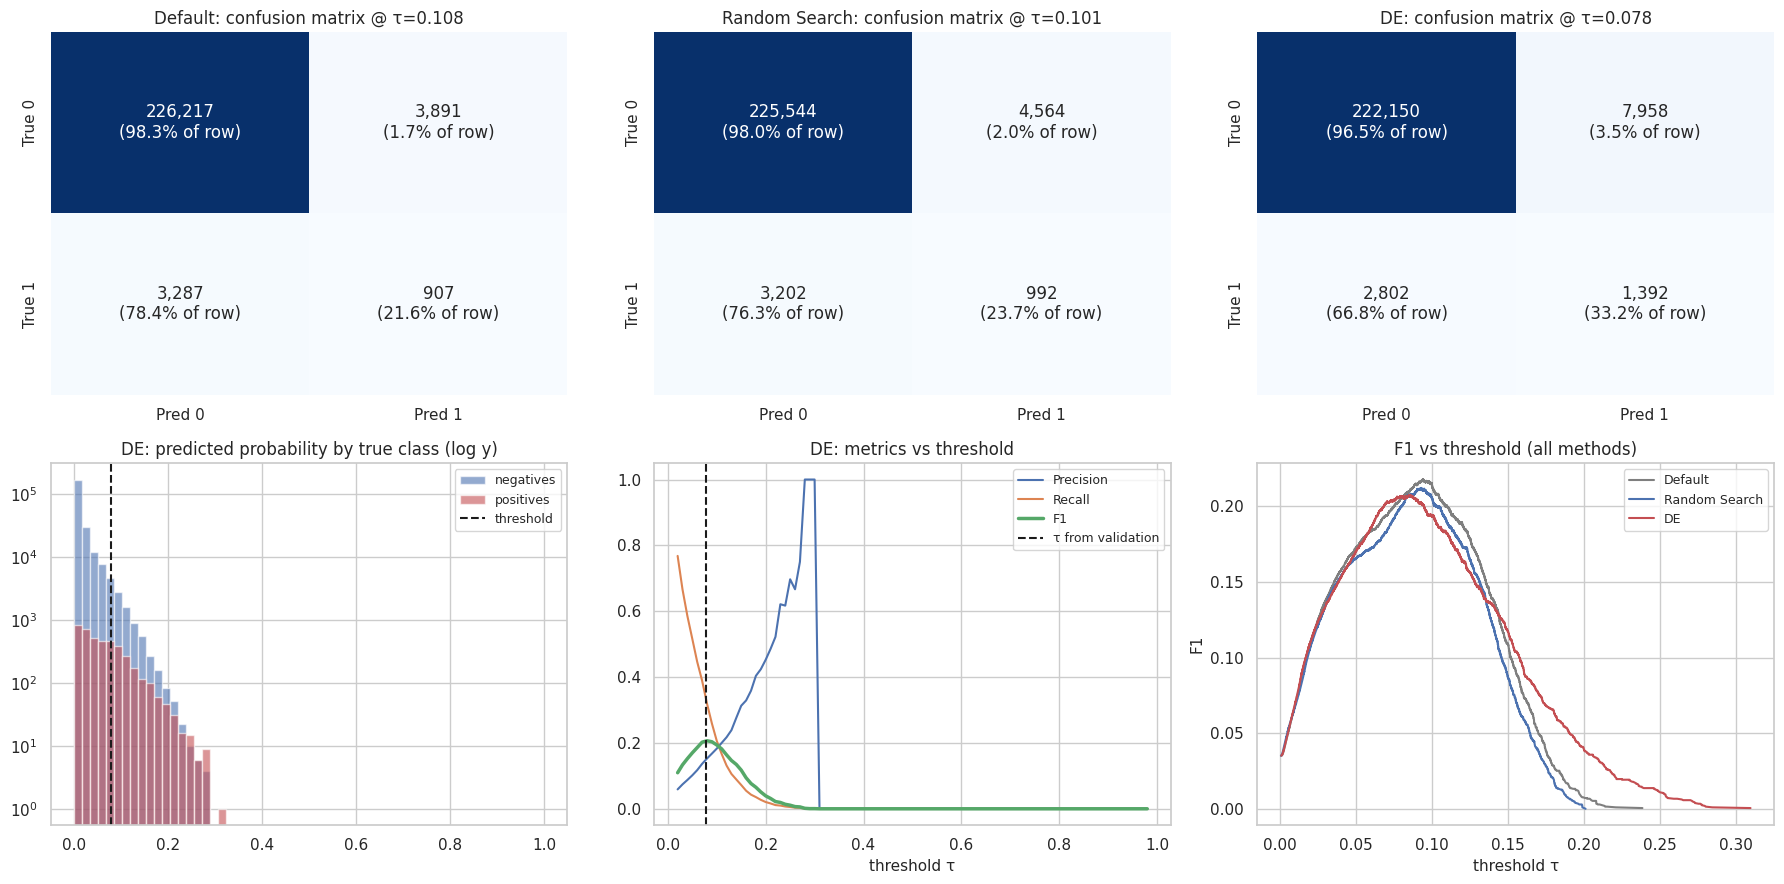

In [31]:
# ---- Figure 14 : matrices de confusion + distribution des scores + analyse du seuil (modèle DE) ----
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
for a, (m, r) in zip(ax[0], REP.items()):
    cmx = confusion_matrix(y_test, (r["pt"] >= r["thr"]).astype(int), labels=[0, 1])
    sns.heatmap(cmx, annot=np.array([[f"{v:,}\n({100*v/cmx[i].sum():.1f}% of row)" for v in cmx[i]] for i in range(2)]), fmt="", cmap="Blues",
                cbar=False, ax=a, xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
    a.set_title(f"{m}: confusion matrix @ τ={r['thr']:.3f}")
rd = REP["DE"]
bins = np.linspace(0, 1, 60)
ax[1, 0].hist(rd["pt"][y_test == 0], bins=bins, alpha=.6, color="#4c72b0", label="negatives"); ax[1, 0].hist(rd["pt"][y_test == 1], bins=bins, alpha=.6, color="#c44e52", label="positives")
ax[1, 0].axvline(rd["thr"], color="k", ls="--", label="threshold"); ax[1, 0].set_yscale("log"); ax[1, 0].set_title("DE: predicted probability by true class (log y)"); ax[1, 0].legend()
ths = np.linspace(0.02, 0.98, 97); P_, R_, F_ = [], [], []
for t in ths:
    mm = compute_metrics(y_test, rd["pt"], t); P_.append(mm["Precision"]); R_.append(mm["Recall"]); F_.append(mm["F1"])
ax[1, 1].plot(ths, P_, label="Precision"); ax[1, 1].plot(ths, R_, label="Recall"); ax[1, 1].plot(ths, F_, label="F1", lw=2.5)
ax[1, 1].axvline(rd["thr"], color="k", ls="--", label="τ from validation"); ax[1, 1].set_xlabel("threshold τ"); ax[1, 1].set_title("DE: metrics vs threshold"); ax[1, 1].legend()
for m, r in REP.items():
    pr_, rc_, th_ = precision_recall_curve(y_test, r["pt"])
    ax[1, 2].plot(th_, (2 * pr_[:-1] * rc_[:-1] / np.maximum(pr_[:-1] + rc_[:-1], 1e-12)), color=PAL[m], label=m)
ax[1, 2].set_xlabel("threshold τ"); ax[1, 2].set_ylabel("F1"); ax[1, 2].set_title("F1 vs threshold (all methods)"); ax[1, 2].legend()
save_fig("F14_confusion_scores_threshold")

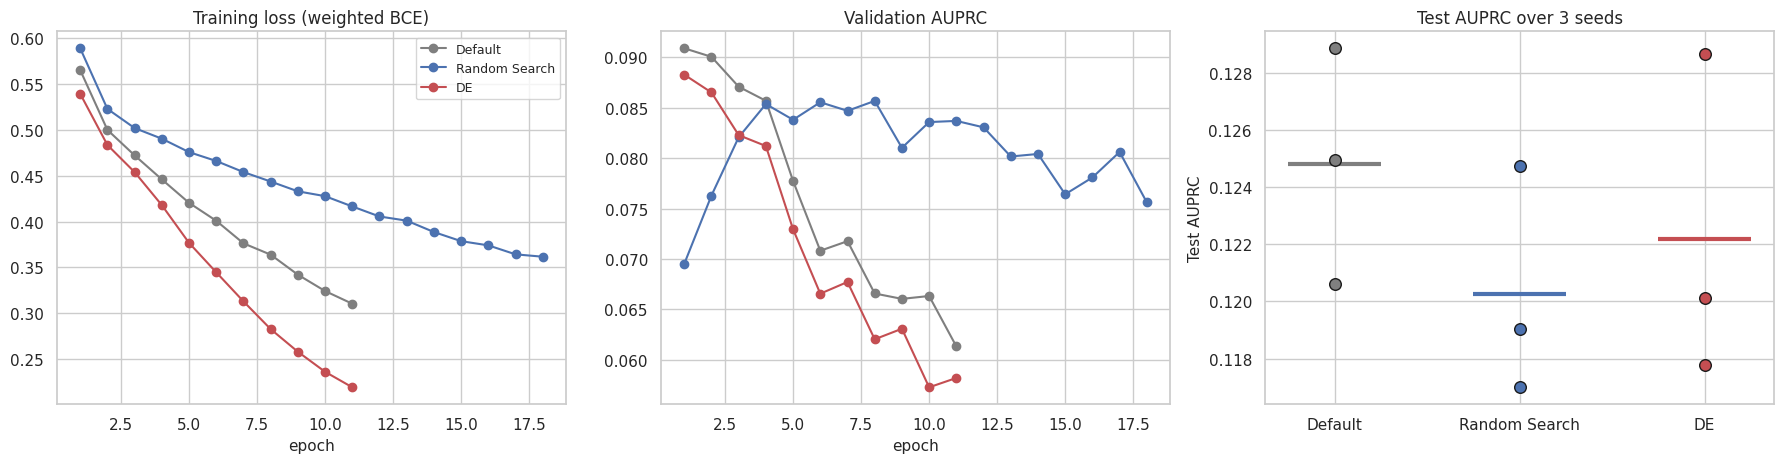

In [32]:
# ---- Figure 15 : courbes d'entraînement + comparaison des seeds ----
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for m, r in REP.items():
    h = r["history"]; ax[0].plot(h.epoch, h.train_loss, "o-", color=PAL[m], label=m); ax[1].plot(h.epoch, h.val_auprc, "o-", color=PAL[m], label=m)
ax[0].set_title("Training loss (weighted BCE)"); ax[0].set_xlabel("epoch"); ax[1].set_title("Validation AUPRC"); ax[1].set_xlabel("epoch"); ax[0].legend()
for i, m in enumerate(BEST_HP):
    v = raw[raw.Method == m].AUPRC.values; ax[2].scatter([i] * len(v), v, s=70, color=PAL[m], edgecolor="k", zorder=3)
    ax[2].hlines(v.mean(), i - .25, i + .25, color=PAL[m], lw=3)
ax[2].set_xticks(range(3)); ax[2].set_xticklabels(list(BEST_HP)); ax[2].set_ylabel("Test AUPRC"); ax[2].set_title(f"Test AUPRC over {CFG['n_seeds']} seeds")
save_fig("F15_training_curves_and_seeds")

,n_sepsis_patients,patient_sensitivity,alarm_before_label_start,median_lead_h,mean_lead_h,false_alarm_patient_rate,false_alarms_per_100_patient_hours
Method,,,,,,,
Default,440,0.3545,0.2500,23.5,45.647400,0.0091,0.2498
Random Search,440,0.3864,0.2682,27.5,45.976501,0.0153,0.3793
DE,440,0.5295,0.3614,24.0,45.227501,0.0569,1.2815


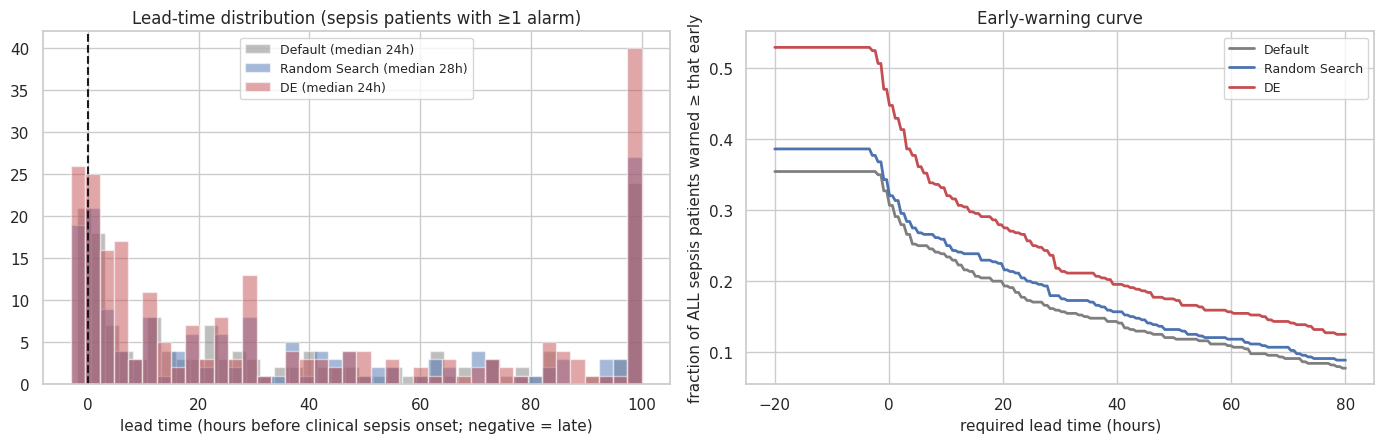

In [33]:
# ---- Tableau 18 + Figure 16 : évaluation au niveau patient ----
def patient_level(pc, it, y, p, thr):
    d = pd.DataFrame(dict(pc=pc, it=it, y=y, al=(p >= thr)))
    ever = d.groupby("pc")["y"].max()
    t_lab = d[d.y == 1].groupby("pc")["it"].min().rename("t_label")
    t_al = d[d.al].groupby("pc")["it"].min().rename("t_alarm")
    res = pd.DataFrame({"ever": ever}).join(t_lab).join(t_al)
    sep, non = res[res.ever == 1], res[res.ever == 0]
    lead = (sep.t_label - sep.t_alarm + 6).dropna()
    nonrows = d[d.pc.isin(non.index)]
    return dict(n_sepsis_patients=len(sep), patient_sensitivity=sep.t_alarm.notna().mean(),
                alarm_before_label_start=(sep.t_alarm <= sep.t_label).mean(),
                median_lead_h=lead.median(), mean_lead_h=lead.mean(),
                false_alarm_patient_rate=non.t_alarm.notna().mean(),
                false_alarms_per_100_patient_hours=100 * nonrows.al.mean()), lead

rows, leads = [], {}
for m, r in REP.items():
    d_, leads[m] = patient_level(pc_test, it_test, y_test, r["pt"], r["thr"]); rows.append(dict(Method=m, **d_))
tab_pat = pd.DataFrame(rows).set_index("Method"); save_table(tab_pat, "T18_patient_level")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for m, l in leads.items(): ax[0].hist(l.clip(-30, 100), bins=40, alpha=.5, color=PAL[m], label=f"{m} (median {l.median():.0f}h)")
ax[0].axvline(0, color="k", ls="--"); ax[0].set_xlabel("lead time (hours before clinical sepsis onset; negative = late)"); ax[0].set_title("Lead-time distribution (sepsis patients with ≥1 alarm)"); ax[0].legend()
for m, l in leads.items():
    xs_ = np.linspace(-20, 80, 200); ax[1].plot(xs_, [(l >= v).mean() * tab_pat.loc[m, "patient_sensitivity"] for v in xs_], color=PAL[m], lw=2, label=m)
ax[1].set_xlabel("required lead time (hours)"); ax[1].set_ylabel("fraction of ALL sepsis patients warned ≥ that early"); ax[1].set_title("Early-warning curve"); ax[1].legend()
save_fig("F16_patient_level_lead_time")

  0%|          | 0/200 [00:00<?, ?it/s]

Mean  CI_low  CI_high
Method        Metric                         
Default       AUPRC   0.1365  0.1151   0.1562
              AUROC   0.8503  0.8348   0.8643
Random Search AUPRC   0.1299  0.1097   0.1516
              AUROC   0.8490  0.8344   0.8634
DE            AUPRC   0.1365  0.1125   0.1577
              AUROC   0.8498  0.8356   0.8632

Mean Δ  CI_low  CI_high  P(Δ ≤ 0)
Comparison         Metric                                   
DE − Default       AUPRC  -0.0001 -0.0135   0.0123     0.500
                   AUROC  -0.0006 -0.0061   0.0045     0.565
DE − Random Search AUPRC   0.0065 -0.0061   0.0175     0.150
                   AUROC   0.0007 -0.0057   0.0074     0.430

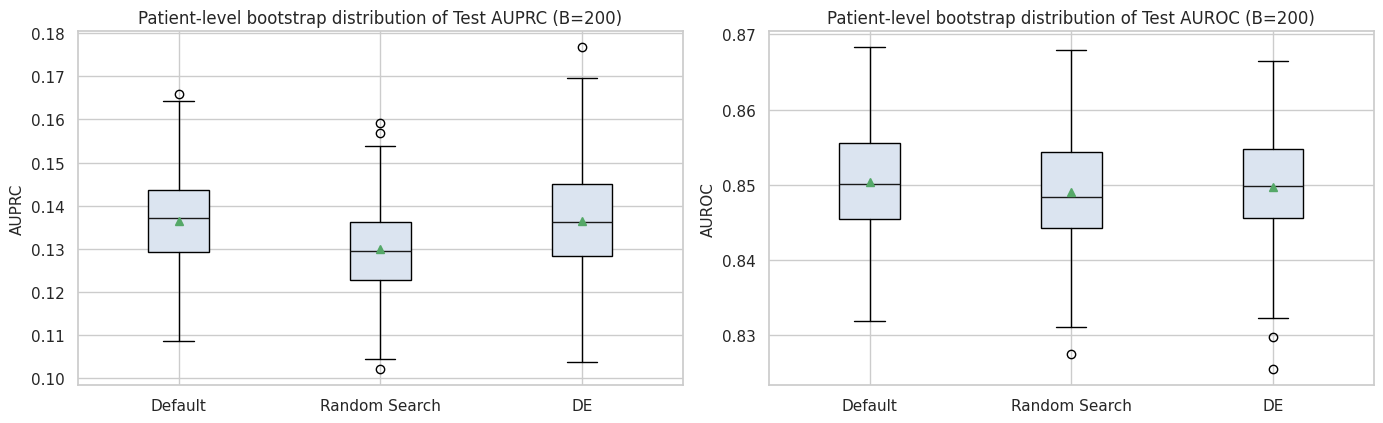

In [34]:
# ---- Figure 17 + Tableaux 19/20 : Bootstrap apparié au niveau patient ----
uniq, st = np.unique(pc_test, return_index=True); en = np.r_[st[1:], len(pc_test)]
rb = np.random.default_rng(SEED); B = CFG["boot"]
probs = {m: REP[m]["pt"] for m in BEST_HP}
bs = {m: {"AUPRC": [], "AUROC": []} for m in BEST_HP}
for b in tqdm(range(B)):
    sel = rb.integers(0, len(uniq), len(uniq))
    idx = np.concatenate([np.arange(st[k], en[k]) for k in sel]); yy = y_test[idx]
    if yy.sum() == 0: continue
    for m in BEST_HP:
        bs[m]["AUPRC"].append(average_precision_score(yy, probs[m][idx])); bs[m]["AUROC"].append(roc_auc_score(yy, probs[m][idx]))
ci = []
for m in BEST_HP:
    for k in ("AUPRC", "AUROC"):
        a = np.array(bs[m][k]); ci.append(dict(Method=m, Metric=k, Mean=a.mean(), CI_low=np.percentile(a, 2.5), CI_high=np.percentile(a, 97.5)))
save_table(pd.DataFrame(ci).set_index(["Method", "Metric"]), "T19_bootstrap_CI")

drows = []
for other in ["Default", "Random Search"]:
    for k in ("AUPRC", "AUROC"):
        dlt = np.array(bs["DE"][k]) - np.array(bs[other][k])
        drows.append({"Comparison": f"DE − {other}", "Metric": k, "Mean Δ": dlt.mean(), "CI_low": np.percentile(dlt, 2.5),
                      "CI_high": np.percentile(dlt, 97.5), "P(Δ ≤ 0)": (dlt <= 0).mean()})
tab_diff = pd.DataFrame(drows).set_index(["Comparison", "Metric"]); save_table(tab_diff, "T20_paired_bootstrap_differences")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for a, k in zip(ax, ("AUPRC", "AUROC")):
    a.boxplot([bs[m][k] for m in BEST_HP], showmeans=True, patch_artist=True,
              boxprops=dict(facecolor="#dbe4f0"), medianprops=dict(color="k"))
    a.set_xticklabels(list(BEST_HP))
    a.set_title(f"Patient-level bootstrap distribution of Test {k} (B={len(bs['DE'][k])})"); a.set_ylabel(k)
save_fig("F17_bootstrap_distributions")

## 9) Conclusion : rôle et robustesse de DE (générée automatiquement à partir des résultats de cette exécution)

In [35]:
def f4(v): return f"{v:.4f}"
d_def = tab_diff.loc[("DE − Default", "AUPRC")]; d_rs = tab_diff.loc[("DE − Random Search", "AUPRC")]
m_ = raw.groupby("Method")["AUPRC"].mean()
lines = [
 "══════════════ Résumé des résultats ══════════════",
 f"1) Pendant la recherche (Validation, {N_BUDGET} évaluations par méthode) : Default={f4(DEFAULT_SEARCH_AP)} | RS best={f4(brs.val_auprc)} | DE best={f4(bde.val_auprc)}",
 f"   • Proportion d'essais meilleurs que Default : DE={tab_stats.loc['DE','% evals > Default']:.0f}% contre RS={tab_stats.loc['Random Search','% evals > Default']:.0f}%",
 f"   • Qualité moyenne des essais : DE={f4(tab_stats.loc['DE','Mean AUPRC'])} contre RS={f4(tab_stats.loc['Random Search','Mean AUPRC'])} (DE concentre-t-il les échantillons dans la bonne région ?)",
 f"2) Sur Test (moyenne de {CFG['n_seeds']} seeds) : Default={f4(m_['Default'])} | RS={f4(m_['Random Search'])} | DE={f4(m_['DE'])}",
 f"   • Ensemble des seeds (modèle final évalué) : Default={f4(REP['Default']['metrics']['AUPRC'])} | RS={f4(REP['Random Search']['metrics']['AUPRC'])} | DE={f4(REP['DE']['metrics']['AUPRC'])}",
 f"   • DE − Default: ΔAUPRC={d_def['Mean Δ']:+.4f}  IC95%=[{d_def['CI_low']:+.4f}, {d_def['CI_high']:+.4f}]  P(Δ≤0)={d_def['P(Δ ≤ 0)']:.3f}",
 f"   • DE − RS     : ΔAUPRC={d_rs['Mean Δ']:+.4f}  IC95%=[{d_rs['CI_low']:+.4f}, {d_rs['CI_high']:+.4f}]  P(Δ≤0)={d_rs['P(Δ ≤ 0)']:.3f}",
 f"3) Efficacité : DE " + (f"a égalé le meilleur résultat final de RS après {int(n_match)} évaluations sur {N_BUDGET}." if not np.isnan(n_match) else "n'a pas égalé le meilleur résultat final de RS dans le budget imparti."),
 f"4) Paramètres les plus corrélés à la performance : " + ", ".join(f"{i} (ρ={imp.loc[i,'Spearman ρ (pooled)']:+.2f})" for i in imp.index[:3]),
 f"5) Sur les fonctions de référence, DE a surpassé Random Search sur {sum(t['DE_mean'] < t['RS_mean'] for t in tests)} fonctions sur {len(tests)}.",
]
print("\n".join(lines))

══════════════ Résumé des résultats ══════════════
1) Pendant la recherche (Validation, 220 évaluations par méthode) : Default=0.0905 | RS best=0.0908 | DE best=0.0952
   • Proportion d'essais meilleurs que Default : DE=16% contre RS=0%
   • Qualité moyenne des essais : DE=0.0865 contre RS=0.0781 (DE concentre-t-il les échantillons dans la bonne région ?)
2) Sur Test (moyenne de 3 seeds) : Default=0.1248 | RS=0.1203 | DE=0.1222
   • Ensemble des seeds (modèle final évalué) : Default=0.1343 | RS=0.1277 | DE=0.1341
   • DE − Default: ΔAUPRC=-0.0001  IC95%=[-0.0135, +0.0123]  P(Δ≤0)=0.500
   • DE − RS     : ΔAUPRC=+0.0065  IC95%=[-0.0061, +0.0175]  P(Δ≤0)=0.150
3) Efficacité : DE a égalé le meilleur résultat final de RS après 49 évaluations sur 220.
4) Paramètres les plus corrélés à la performance : log10_lr (ρ=+0.85), dropout (ρ=-0.44), window (ρ=+0.40)
5) Sur les fonctions de référence, DE a surpassé Random Search sur 4 fonctions sur 4.


### Comment lire ces résultats (interprétation scientifique)

**Rôle de DE (Role) :** optimiseur global des hyperparamètres du LSTM dans un espace mixte (entier/réel/logarithmique) et de type boîte noire. Il remplace le réglage manuel/par grille par un processus guidé : il explore lors des premières générations (diversité élevée) puis exploite la région prometteuse (diversité en baisse, taux de succès en recul).

**Robustesse de DE (Strength) — comment en juger ?**
1. **Efficacité :** la courbe best-so-far de DE est au-dessus de RS et/ou atteint le niveau final de RS avec moins d'évaluations (Tableau 13 et Figure 8).
2. **Concentration :** l'ECDF de DE est décalée vers la droite et la proportion d'essais « excellents » est plus élevée (Tableau 12, Figure 12) = DE n'améliore pas seulement « le meilleur point » mais **élève la qualité des échantillons** en général.
3. **Généralisation :** la différence persiste sur **Test** avec un intervalle de confiance qui ne contient pas zéro ($\hat P(\Delta\le0)$ petit) — Tableau 20. C'est la preuve la plus importante car elle est hors des données de sélection.
4. **Test indépendant :** sur les fonctions de référence (Tableaux 5–6, Figure 5) apparaissent les propriétés de l'algorithme sans le bruit de l'entraînement.

**Avertissements méthodologiques à mentionner dans tout rapport :**
- Des différences très faibles (par exemple 0.002 en AUPRC) peuvent être **dans le bruit** ; c'est pourquoi nous utilisons plusieurs seeds et un Bootstrap apparié.
- Petit budget ($NP\cdot(G+1)\approx$ 50–100) avec un espace à 6 dimensions : DE n'est pas dans sa meilleure situation (règle habituelle $NP\approx5D\!-\!10D$ et $G$ de l'ordre de plusieurs dizaines). Passer `MODE` à `medium/full` montre l'écart plus clairement.
- La fonction objectif est estimée par un entraînement court ; le classement peut légèrement changer avec un entraînement complet (c'est pourquoi nous ré-entraînons complètement et évaluons sur Test).
- La différence entre les deux hôpitaux (A et B) = **décalage de distribution** ; la généralisation d'un modèle à un nouvel hôpital nécessite une évaluation externe (par exemple entraîner sur A et tester sur B).
- Ceci n'est pas un dispositif médical ; la métrique officielle du challenge est le Utility Score, qui peut être ajouté comme fonction objectif alternative ou multi-objectif (NSGA-II/MODE).

**Extensions proposées :** (1) DE multi-objectif (AUPRC contre délai d'alerte/taille du modèle), (2) ajouter l'architecture du réseau (GRU/Attention/Transformer) comme variable catégorielle, (3) recherche conjointe sur le ratio d'échantillonnage `neg_ratio` et `pos_weight`, (4) évaluer DE contre l'optimisation bayésienne (Optuna/TPE) avec le même budget.

In [36]:
# ---- Sauvegarde de toutes les sorties (figures + tableaux + meilleurs paramètres) dans un fichier ZIP ----
with zipfile.ZipFile("sepsis_de_lstm_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for p in list(FIG_DIR.glob("*.png")) + list(TAB_DIR.glob("*.csv")) + [Path("best_hyperparameters.json")]:
        z.write(p)
print("Sauvegardé :", len(list(FIG_DIR.glob('*.png'))), "figures,", len(list(TAB_DIR.glob('*.csv'))), "tableaux ← sepsis_de_lstm_results.zip")

Sauvegardé : 18 figures, 21 tableaux ← sepsis_de_lstm_results.zip
